# EIGER correction trends across scans

Read-only analysis of the fast calibration files directly in **outputs** (not archived subdirectories). Run from the top; configuration is in the next cell. Map comparisons need only saved calibrations; the later **time/count exposure section additionally streams original detector frames** and requires their source NeXus/companion files plus `hdf5plugin`. No refitting or exports are performed.

**Bad-pixel candidates are not confirmed dead pixels.** The saved `bad_pixel_mask` flags persistent fit outliers, including possible hot or unstable pixels. The base mask also contains detector boundaries and native masked pixels. A truly dead-pixel count requires raw-count evidence beyond the saved flag.

Map comparisons use pixels supported and valid in **every selected scan**, without smoothing or differencing across sensor boundaries. Graininess and ridge RMS are noise-sensitive diagnostics; fixed signed pattern amplitudes provide a separate recurring-structure measure. Scan number is an ordering coordinate, **not elapsed time**. The time/count section reconstructs real acquisition times and cumulative valid raw counts including intervening scans, relative to a stated baseline; recorded counts are an exposure proxy, not absorbed dose.

Calibration files do not provide reliable sample/collection labels: the filename prefix is displayed as a run prefix, and optional manual collection labels can be supplied.

In [1]:
from pathlib import Path
import hashlib
import json
import re
import warnings

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter
from IPython.display import display

REPO_DIRECTORY = Path.cwd().resolve()
while REPO_DIRECTORY != REPO_DIRECTORY.parent and not (REPO_DIRECTORY / 'eiger_workflow.py').exists():
    REPO_DIRECTORY = REPO_DIRECTORY.parent
if not (REPO_DIRECTORY / 'eiger_workflow.py').exists():
    raise FileNotFoundError('Launch this notebook from the repository or a subdirectory.')

INPUT_DIRECTORY = REPO_DIRECTORY / 'outputs'
FILE_PATTERN = '*_detector_corrections_fast.h5'
SCAN_RANGE = None  # Optional inclusive (first_scan, last_scan).
REFERENCE_SCAN = None  # None: earliest selected scan.
SMOOTH_SIGMA_PIXELS = 2.0
MIN_OBSERVATIONS = None  # None: each saved fit minimum; overrides can only raise it.
TOP_FEATURE_COUNT = 8
FEATURE_MIN_SEPARATION_PIXELS = 12
FEATURE_PIXELS = []  # Optional fixed [(row, column), ...], zero-based.
MAP_SCANS = None  # None: up to six evenly spaced selected scans.
COLLECTION_LABELS = {}  # Optional {100578: 'sample A', 100582: 'sample B', ...}.

if not np.isfinite(SMOOTH_SIGMA_PIXELS) or SMOOTH_SIGMA_PIXELS <= 0:
    raise ValueError('SMOOTH_SIGMA_PIXELS must be finite and positive.')
if MIN_OBSERVATIONS is not None and (not isinstance(MIN_OBSERVATIONS, (int, np.integer)) or MIN_OBSERVATIONS < 1):
    raise ValueError('MIN_OBSERVATIONS must be None or a positive integer.')
if not isinstance(TOP_FEATURE_COUNT, (int, np.integer)) or TOP_FEATURE_COUNT < 1:
    raise ValueError('TOP_FEATURE_COUNT must be a positive integer.')
if not np.isfinite(FEATURE_MIN_SEPARATION_PIXELS) or FEATURE_MIN_SEPARATION_PIXELS < 1:
    raise ValueError('FEATURE_MIN_SEPARATION_PIXELS must be at least one pixel.')

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': False, 'font.size': 10})
pd.set_option('display.max_columns', 40)

# 1. Discovery is deliberately nonrecursive, excluding outputs/old_corrections.
pattern = re.compile(r'^(?P<prefix>.+)-(?P<scan>[0-9]+)_detector_corrections_fast[.]h5$')
file_rows = []
for path in INPUT_DIRECTORY.glob(FILE_PATTERN):
    match = pattern.fullmatch(path.name)
    if match is None:
        raise ValueError(f'Cannot parse scan number from {path.name}')
    scan = int(match['scan'])
    if SCAN_RANGE is not None and not SCAN_RANGE[0] <= scan <= SCAN_RANGE[1]:
        continue
    file_rows.append({'scan': scan, 'run_prefix': match['prefix'],
                      'collection': COLLECTION_LABELS.get(scan, match['prefix']), 'path': path})
if not file_rows:
    raise FileNotFoundError(f'No selected {FILE_PATTERN} files in {INPUT_DIRECTORY}')
files = pd.DataFrame(file_rows).sort_values('scan').set_index('scan')
if files.index.has_duplicates:
    raise ValueError('Duplicate scan numbers: narrow the input selection before comparing.')
scans = files.index.to_numpy(dtype=int)
reference_scan = int(scans[0] if REFERENCE_SCAN is None else REFERENCE_SCAN)
if reference_scan not in files.index:
    raise ValueError('REFERENCE_SCAN is not in the selected files.')
reference_index = int(np.flatnonzero(scans == reference_scan)[0])
print(f'{len(files)} calibrations; scans {scans[0]}–{scans[-1]}; reference {reference_scan}')
display(files)

15 calibrations; scans 100578–100609; reference 100578


,run_prefix,collection,path
scan,,,
100578,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100582,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100584,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100585,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100587,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100589,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100591,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100593,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...
100595,i15-1,i15-1,/dls/science/users/fer45166/eiger-correction/o...


## Load saved maps and check comparability

Files are opened read-only. Texture excludes base masks, fitted bad-pixel candidates, nonpositive/nonfinite divisors and pixels below the fit's minimum observation count. The intersection across scans is held fixed, so changing coverage cannot directly change the texture statistic. Geometry/fit differences are reported as possible confounders, not silently assumed equivalent. Sensor IDs are zero-based internally and labelled 1–8 in figures.

In [2]:
def text(value):
    return value.decode() if isinstance(value, bytes) else str(value)


records, metadata_rows = [], []
for scan, row in files.iterrows():
    with h5py.File(row.path, 'r') as handle:
        correction = handle['corrections']
        record = {key: correction[key][()] for key in (
            'combined_divisor', 'pixel_divisor', 'sensor_gains', 'bad_pixel_mask',
            'base_mask', 'sensor_ids', 'observations')}
        settings = json.loads(text(handle.attrs['fit_settings_json']))
        threshold = max(int(settings.get('minimum_observations', 8)), MIN_OBSERVATIONS or 0)
        record['valid'] = (~record['base_mask'].astype(bool) & ~record['bad_pixel_mask'].astype(bool)
                           & (record['sensor_ids'] >= 0) & (record['observations'] >= threshold)
                           & np.isfinite(record['combined_divisor']) & (record['combined_divisor'] > 0))
        geometry_hash = hashlib.sha256(text(handle['geometry_json'][()]).encode()).hexdigest()[:12]
        metadata_rows.append({
            'scan': scan, 'collection': row.collection,
            'bad_candidates_total': int(np.count_nonzero(record['bad_pixel_mask'])),
            'bad_candidates_outside_base': int(np.count_nonzero(record['bad_pixel_mask'].astype(bool)
                                                               & ~record['base_mask'].astype(bool))),
            'base_mask_pixels': int(np.count_nonzero(record['base_mask'])),
            'supported_valid_pixels': int(record['valid'].sum()),
            'minimum_observations': threshold,
            'geometry_hash': geometry_hash,
            'q_range': str(settings.get('q_range')),
            'fit_bins': settings.get('npt'), 'iterations': settings.get('iterations'),
            'source_frames': settings.get('angle_aggregation', {}).get('source_frame_count'),
            'analysis_positions': len(handle['fit_diagnostics/frame_angles_deg']),
            'energy_kev': handle['physical'].attrs.get('energy_kev', np.nan),
        })
    records.append(record)

sensor_ids = records[0]['sensor_ids']
for record in records:
    if record['combined_divisor'].shape != sensor_ids.shape:
        raise ValueError('Detector shapes differ; do not compare unregistered maps.')
    np.testing.assert_array_equal(record['sensor_ids'], sensor_ids)
    if record['sensor_gains'].shape != (8,) or not np.all(np.isfinite(record['sensor_gains']) & (record['sensor_gains'] > 0)):
        raise ValueError('Expected eight finite positive sensor gains.')
common_valid = np.logical_and.reduce([record['valid'] for record in records])
if not common_valid.any():
    raise ValueError('No commonly supported valid pixels. Narrow SCAN_RANGE.')
summary = pd.DataFrame(metadata_rows).set_index('scan')
for field in ('geometry_hash', 'q_range', 'fit_bins', 'iterations', 'minimum_observations', 'energy_kev'):
    if summary[field].nunique(dropna=False) > 1:
        warnings.warn(f'{field} differs across files; apparent trends may reflect calibration settings.')
print(f'Fixed comparison support: {common_valid.sum():,} pixels of {common_valid.size:,}')
display(summary)


Fixed comparison support: 508,912 pixels of 526,336


,collection,bad_candidates_total,bad_candidates_outside_base,base_mask_pixels,supported_valid_pixels,minimum_observations,geometry_hash,q_range,fit_bins,iterations,source_frames,analysis_positions,energy_kev
scan,,,,,,,,,,,,,
100578,i15-1,39,39,17323,508974,8,4d3014efa448,"[200.0, 400.0]",800,10,81,81,76.7
100582,i15-1,1,1,17323,509012,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7
100584,i15-1,1,1,17323,509012,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7
100585,i15-1,21,21,17323,508992,8,4d3014efa448,"[200.0, 400.0]",800,10,31,31,76.7
100587,i15-1,30,30,17323,508983,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7
100589,i15-1,31,31,17323,508982,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7
100591,i15-1,29,29,17323,508984,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7
100593,i15-1,31,31,17323,508982,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7
100595,i15-1,36,36,17323,508977,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7


## Bad-pixel candidates and eight sensor gains

“New” and “recovered” compare candidate masks with the **previous available scan**, not the previous integer scan. A disappearing flag does not prove physical recovery. The recurrence map shows where flags persist. Gains are **divisors** (counts are divided by them); the lower panel shows relative change from the selected reference.

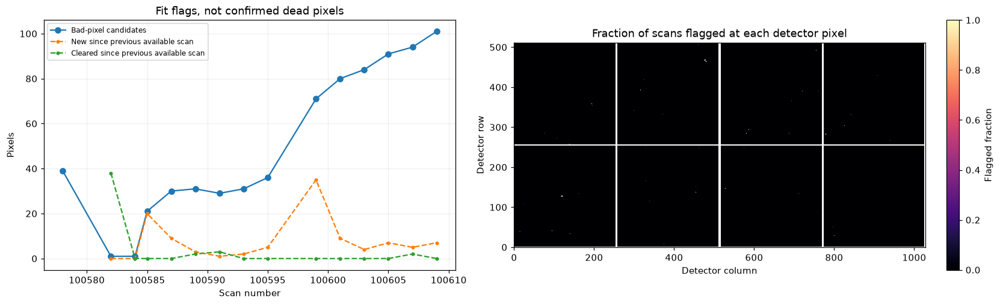

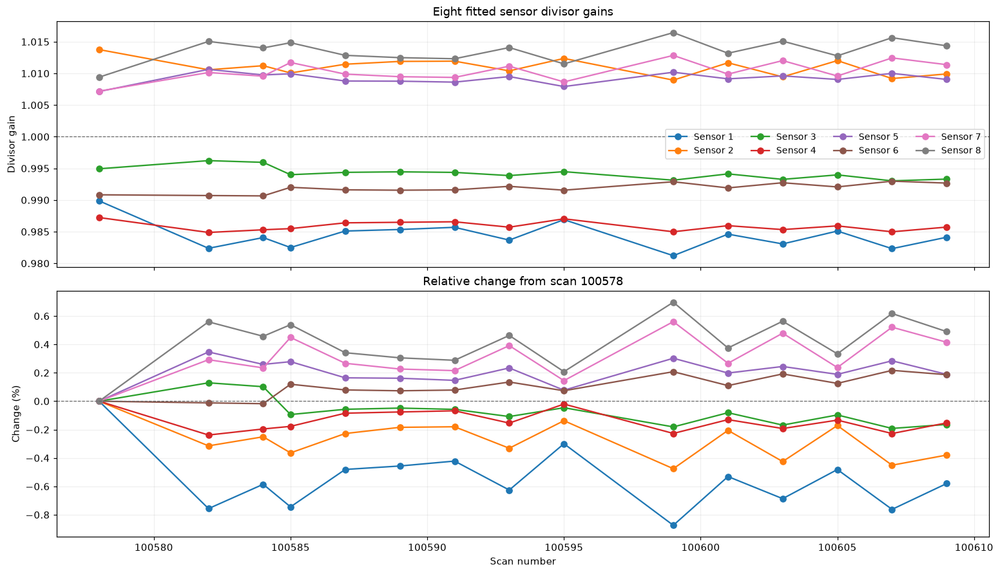

,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8
scan,,,,,,,,
100578,0.989866,1.013760,0.994938,0.987235,1.007143,0.990828,1.007199,1.009408
100582,0.982377,1.010571,0.996226,0.984883,1.010637,0.990710,1.010143,1.015050
100584,0.984072,1.011219,0.995954,0.985304,1.009753,0.990655,1.009562,1.014024
100585,0.982498,1.010070,0.994004,0.985485,1.009948,0.992012,1.011723,1.014847
100587,0.985108,1.011452,0.994371,0.986401,1.008802,0.991614,1.009888,1.012855
100589,0.985348,1.011894,0.994456,0.986486,1.008772,0.991555,1.009481,1.012491
100591,0.985691,1.011935,0.994365,0.986568,1.008622,0.991607,1.009367,1.012317
100593,0.983673,1.010402,0.993863,0.985713,1.009502,0.992166,1.011143,1.014084
100595,0.986901,1.012368,0.994481,0.987035,1.007924,0.991558,1.008658,1.011507


In [3]:
bad_stack = np.stack([r['bad_pixel_mask'].astype(bool) & ~r['base_mask'].astype(bool) for r in records])
new_flags = np.full(len(scans), np.nan)
recovered_flags = new_flags.copy()
for i in range(1, len(scans)):
    new_flags[i] = np.count_nonzero(bad_stack[i] & ~bad_stack[i - 1])
    recovered_flags[i] = np.count_nonzero(bad_stack[i - 1] & ~bad_stack[i])
summary['new_flags_vs_previous'] = new_flags
summary['cleared_flags_vs_previous'] = recovered_flags
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
axes[0].plot(scans, summary['bad_candidates_outside_base'], 'o-', label='Bad-pixel candidates')
axes[0].plot(scans, new_flags, '.--', label='New since previous available scan')
axes[0].plot(scans, recovered_flags, '.--', label='Cleared since previous available scan')
axes[0].set(xlabel='Scan number', ylabel='Pixels', title='Fit flags, not confirmed dead pixels')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.2)
recurrence = np.ma.array(bad_stack.mean(axis=0), mask=records[0]['base_mask'].astype(bool))
image = axes[1].imshow(recurrence, origin='lower', cmap='magma', vmin=0, vmax=1, interpolation='nearest')
axes[1].set(title='Fraction of scans flagged at each detector pixel', xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=axes[1], label='Flagged fraction')
plt.show()

sensor_gains = np.stack([record['sensor_gains'] for record in records])
sensor_gain_table = pd.DataFrame(sensor_gains, index=files.index,
                                 columns=[f'sensor_{i + 1}' for i in range(8)])
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, constrained_layout=True)
for sensor in range(8):
    color = plt.get_cmap('tab10')(sensor)
    axes[0].plot(scans, sensor_gains[:, sensor], 'o-', color=color, label=f'Sensor {sensor + 1}')
    axes[1].plot(scans, 100 * (sensor_gains[:, sensor] / sensor_gains[reference_index, sensor] - 1),
                 'o-', color=color)
axes[0].axhline(1, color='0.4', lw=0.8, ls='--')
axes[0].set(title='Eight fitted sensor divisor gains', ylabel='Divisor gain')
axes[0].legend(ncol=4, fontsize=9)
axes[1].axhline(0, color='0.4', lw=0.8, ls='--')
axes[1].set(title=f'Relative change from scan {reference_scan}', ylabel='Change (%)', xlabel='Scan number')
for ax in axes:
    ax.grid(alpha=0.2)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.show()
display(sensor_gain_table)


## Graininess and sharp structure, separated from sensor offsets

Texture is measured on `100 × log(combined_divisor)`, approximately percent for small variations. Within each sensor we remove its median and then subtract a mask-normalized Gaussian smooth (`SMOOTH_SIGMA_PIXELS`). No other sensor or excluded pixel contributes to the smooth. This **high-pass residual** isolates fine structure; it is not a noise-only estimate.

- **Robust graininess:** 1.4826 × median absolute deviation of the high-pass residual.
- **RMS and 99th percentile absolute residual:** more sensitive to sparse sharp features.
- **Nearest-neighbour RMS / √2:** uses only adjacent valid pixels in the same sensor; equals noise sigma only for independent equal-variance noise.
- **Reference difference:** RMS high-pass change, holding the detector coordinates and support fixed.

Differences may reflect sample structure, counting statistics, scan sampling or fit regularization as well as detector response. These are descriptive measures, not evidence of detector ageing.

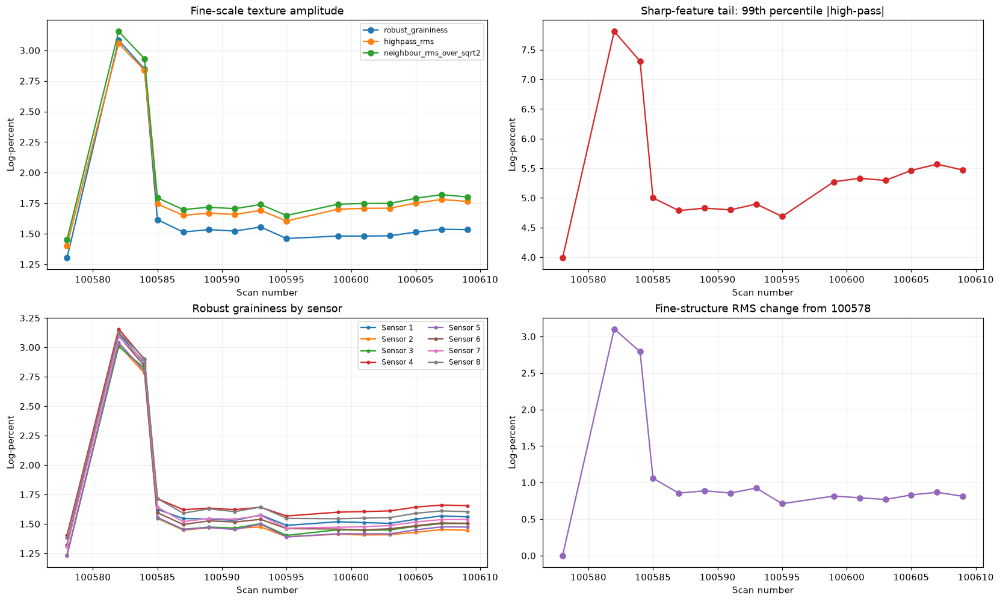

,robust_graininess,highpass_rms,highpass_p99_abs,neighbour_rms_over_sqrt2,highpass_change_rms
scan,,,,,
100578,1.3016,1.4039,3.9866,1.4516,0.0000
100582,3.0831,3.0559,7.8087,3.1557,3.1023
100584,2.8482,2.8384,7.3046,2.9313,2.7917
100585,1.6151,1.7437,5.0005,1.7940,1.0592
100587,1.5140,1.6510,4.7862,1.6979,0.8548
100589,1.5340,1.6687,4.8272,1.7169,0.8875
100591,1.5218,1.6579,4.7988,1.7050,0.8563
100593,1.5551,1.6913,4.8963,1.7391,0.9251
100595,1.4608,1.6045,4.6867,1.6494,0.7103


In [4]:
def robust_sigma(values):
    return 1.4826 * np.median(np.abs(values - np.median(values)))


def sensor_highpass(divisor):
    residual = np.full(sensor_ids.shape, np.nan)
    for sensor in range(8):
        support = common_valid & (sensor_ids == sensor)
        if not support.any():
            continue
        rr, cc = np.where(sensor_ids == sensor)
        region = np.s_[rr.min():rr.max() + 1, cc.min():cc.max() + 1]
        mask = support[region]
        values = np.zeros(mask.shape)
        values[mask] = 100 * np.log(divisor[region][mask])
        values[mask] -= np.median(values[mask])
        weight = gaussian_filter(mask.astype(float), SMOOTH_SIGMA_PIXELS, mode='constant')
        smooth = gaussian_filter(values, SMOOTH_SIGMA_PIXELS, mode='constant') / np.maximum(weight, 1e-15)
        residual[region][mask] = (values - smooth)[mask]
    return residual


highpass = np.stack([sensor_highpass(record['combined_divisor']) for record in records])
assert np.all(np.isfinite(highpass[:, common_valid]))
texture_rows, sensor_texture_rows = [], []
for i, scan in enumerate(scans):
    values = highpass[i][common_valid]
    neighbour_differences = []
    log_divisor = 100 * np.log(np.where(common_valid, records[i]['combined_divisor'], 1.0))
    for axis in (0, 1):
        left = (slice(None, -1), slice(None)) if axis == 0 else (slice(None), slice(None, -1))
        right = (slice(1, None), slice(None)) if axis == 0 else (slice(None), slice(1, None))
        pairs = common_valid[left] & common_valid[right] & (sensor_ids[left] == sensor_ids[right])
        neighbour_differences.append((log_divisor[right] - log_divisor[left])[pairs])
    neighbour_differences = np.concatenate(neighbour_differences)
    texture_rows.append({
        'scan': scan, 'robust_graininess': robust_sigma(values),
        'highpass_rms': np.sqrt(np.mean(values**2)),
        'highpass_p99_abs': np.percentile(np.abs(values), 99),
        'neighbour_rms_over_sqrt2': np.sqrt(np.mean(neighbour_differences**2) / 2)
                                    if neighbour_differences.size else np.nan,
        'highpass_change_rms': np.sqrt(np.mean((values - highpass[reference_index][common_valid])**2)),
    })
    for sensor in range(8):
        sensor_values = highpass[i][common_valid & (sensor_ids == sensor)]
        sensor_texture_rows.append({'scan': scan, 'sensor': sensor + 1,
                                   'robust_graininess': robust_sigma(sensor_values) if sensor_values.size else np.nan})
texture = pd.DataFrame(texture_rows).set_index('scan')
sensor_texture = pd.DataFrame(sensor_texture_rows).pivot(index='scan', columns='sensor', values='robust_graininess')
fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
for field in ('robust_graininess', 'highpass_rms', 'neighbour_rms_over_sqrt2'):
    axes[0, 0].plot(scans, texture[field], 'o-', label=field)
axes[0, 0].set(title='Fine-scale texture amplitude', ylabel='Log-percent')
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(scans, texture['highpass_p99_abs'], 'o-', color='tab:red')
axes[0, 1].set(title='Sharp-feature tail: 99th percentile |high-pass|', ylabel='Log-percent')
for sensor in sensor_texture:
    axes[1, 0].plot(scans, sensor_texture[sensor], '.-', label=f'Sensor {sensor}')
axes[1, 0].set(title='Robust graininess by sensor', ylabel='Log-percent')
axes[1, 0].legend(ncol=2, fontsize=8)
axes[1, 1].plot(scans, texture['highpass_change_rms'], 'o-', color='tab:purple')
axes[1, 1].set(title=f'Fine-structure RMS change from {reference_scan}', ylabel='Log-percent')
for ax in axes.flat:
    ax.set_xlabel('Scan number')
    ax.grid(alpha=0.2)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.show()
display(texture.round(4))


## Fixed-scale detector maps

Each column uses one shared colour scale across scans: the saved combined divisor, its high-pass residual, and high-pass change from the reference. Grey pixels are excluded by the common comparison mask. Set `MAP_SCANS` to specific scan numbers to compare particular collections; all selected scans still enter the statistics.

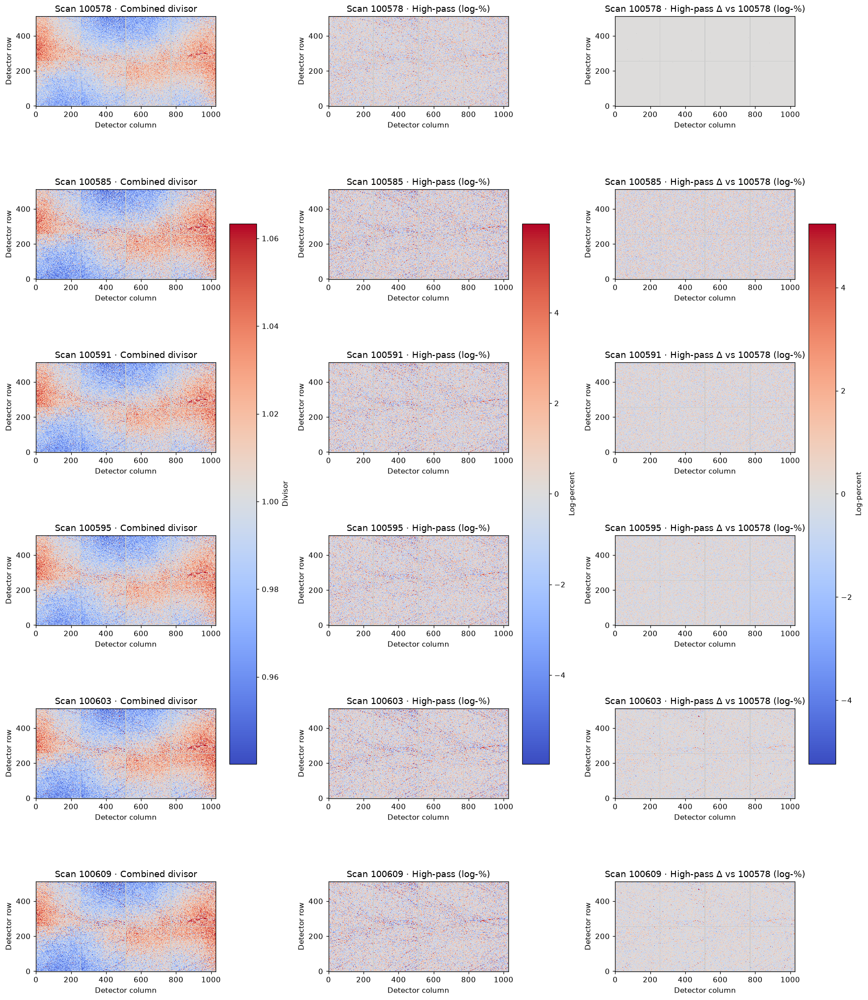

In [5]:
if MAP_SCANS is None:
    map_indices = np.unique(np.linspace(0, len(scans) - 1, min(6, len(scans))).round().astype(int))
else:
    if not MAP_SCANS or any(scan not in files.index for scan in MAP_SCANS):
        raise ValueError('MAP_SCANS must be a nonempty list of selected scan numbers.')
    map_indices = np.array([int(np.flatnonzero(scans == scan)[0]) for scan in MAP_SCANS])
combined_values = np.stack([r['combined_divisor'][common_valid] for r in records])
divisor_limits = np.percentile(combined_values, [1, 99])
hp_limit = max(float(np.percentile(np.abs(highpass[:, common_valid]), 99)), 1e-6)
delta_limit = max(float(np.percentile(np.abs(highpass[:, common_valid] - highpass[reference_index][common_valid]), 99)), 1e-6)
cmap = plt.get_cmap('coolwarm').copy()
cmap.set_bad('0.8')
fig, axes = plt.subplots(len(map_indices), 3, figsize=(16, 3.2 * len(map_indices)),
                         squeeze=False, constrained_layout=True)
for row, i in enumerate(map_indices):
    maps = (records[i]['combined_divisor'], highpass[i], highpass[i] - highpass[reference_index])
    limits = (divisor_limits, (-hp_limit, hp_limit), (-delta_limit, delta_limit))
    for col, (values, lim) in enumerate(zip(maps, limits)):
        image = axes[row, col].imshow(np.ma.array(values, mask=~common_valid), origin='lower',
                                      cmap=cmap, vmin=lim[0], vmax=lim[1], interpolation='nearest')
        axes[row, col].set(title=f'Scan {scans[i]} · ' + ('Combined divisor', 'High-pass (log-%)',
                            f'High-pass Δ vs {reference_scan} (log-%)')[col],
                          xlabel='Detector column', ylabel='Detector row')
        if row == len(map_indices) - 1:
            fig.colorbar(image, ax=axes[:, col].tolist(), shrink=0.6,
                         label='Divisor' if col == 0 else 'Log-percent')
plt.show()


## Track sharp features at fixed detector coordinates

Automatic markers rank pixels by the **across-scan standard deviation of the high-pass residual**, then enforce a minimum spatial separation. They are selected using these same data, so large changes are expected by construction; they are exploratory, not significance tests. Use `FEATURE_PIXELS = [(row, column), ...]` to track known features instead. A bright feature that is stable across scans need not rank highly.

The traces show both the actual saved combined divisor and its local high-pass contrast. Zooms compare the reference with the scan showing the largest contrast change at feature 1. They share colour limits, are clipped to that sensor, and do not alter the calibration. The common mask deliberately excludes pixels flagged in *any* selected scan; the earlier recurrence plot covers those pixels separately.

,row,column,sensor,contrast_std_log_percent,contrast_range_log_percent
feature,,,,,
1,507,342,4,7.591817,24.935333
2,507,460,4,4.158924,12.854362
3,271,337,4,4.087838,20.305905
4,466,479,4,4.072767,13.125057
5,127,118,1,3.920450,11.352201
6,144,459,3,3.723122,12.282248
7,16,548,5,3.569539,11.991755
8,89,1007,7,3.526547,15.202248


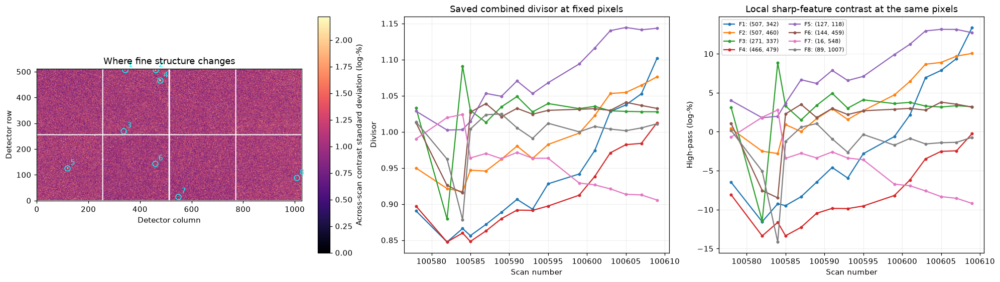

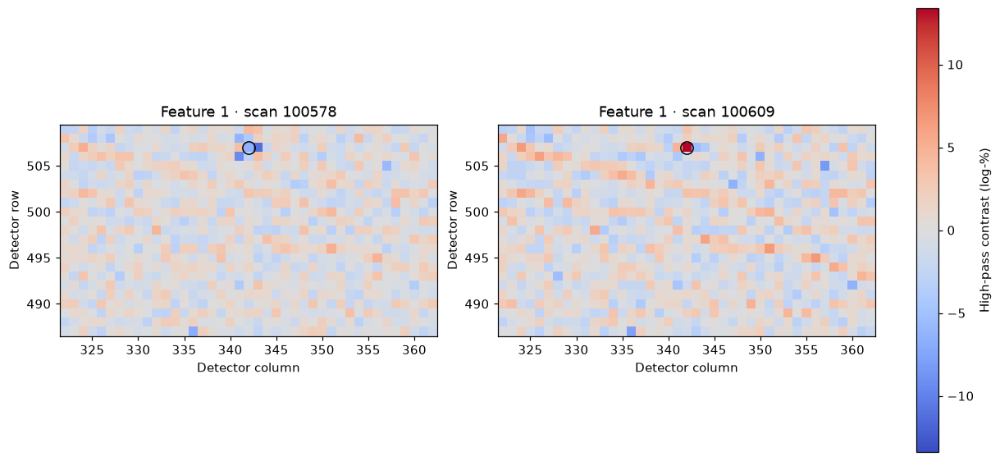

In [6]:
variability = np.full(sensor_ids.shape, np.nan)
variability[common_valid] = np.std(highpass[:, common_valid], axis=0)
if FEATURE_PIXELS:
    feature_pixels = []
    for point in FEATURE_PIXELS:
        if len(point) != 2 or any(not isinstance(v, (int, np.integer)) for v in point):
            raise ValueError('Each FEATURE_PIXELS entry must be an integer (row, column).')
        r, c = point
        if not (0 <= r < common_valid.shape[0] and 0 <= c < common_valid.shape[1]) or not common_valid[r, c]:
            raise ValueError(f'Feature {point} is outside common valid support.')
        feature_pixels.append((r, c))
else:
    feature_pixels = []
    available = np.where(common_valid, variability, -np.inf)
    rr, cc = np.indices(sensor_ids.shape)
    for _ in range(TOP_FEATURE_COUNT):
        r, c = np.unravel_index(np.argmax(available), available.shape)
        if not np.isfinite(available[r, c]):
            break
        feature_pixels.append((int(r), int(c)))
        available[(rr - r)**2 + (cc - c)**2 < FEATURE_MIN_SEPARATION_PIXELS**2] = -np.inf

feature_table = pd.DataFrame([
    {'feature': k + 1, 'row': r, 'column': c, 'sensor': int(sensor_ids[r, c]) + 1,
     'contrast_std_log_percent': variability[r, c],
     'contrast_range_log_percent': np.ptp(highpass[:, r, c])}
    for k, (r, c) in enumerate(feature_pixels)
]).set_index('feature')
display(feature_table)
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
image = axes[0].imshow(np.ma.array(variability, mask=~common_valid), origin='lower', cmap='magma',
                        vmin=0, vmax=max(float(np.percentile(variability[common_valid], 99)), 1e-6))
fig.colorbar(image, ax=axes[0], label='Across-scan contrast standard deviation (log-%)')
axes[0].set(title='Where fine structure changes', xlabel='Detector column', ylabel='Detector row')
for k, (r, c) in enumerate(feature_pixels):
    label = f'F{k + 1}: ({r}, {c})'
    color = plt.get_cmap('tab10')(k % 10)
    axes[0].plot(c, r, 'o', ms=7, mfc='none', mec='cyan')
    axes[0].annotate(str(k + 1), (c, r), xytext=(4, 4), textcoords='offset points', color='cyan')
    axes[1].plot(scans, [record['combined_divisor'][r, c] for record in records], '.-', color=color, label=label)
    axes[2].plot(scans, highpass[:, r, c], '.-', color=color, label=label)
axes[1].set(title='Saved combined divisor at fixed pixels', xlabel='Scan number', ylabel='Divisor')
axes[2].set(title='Local sharp-feature contrast at the same pixels', xlabel='Scan number', ylabel='High-pass (log-%)')
axes[2].legend(fontsize=7, ncol=2)
for ax in axes[1:]:
    ax.grid(alpha=0.2)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.show()

r, c = feature_pixels[0]
changed_index = int(np.argmax(np.abs(highpass[:, r, c] - highpass[reference_index, r, c])))
sensor_region = sensor_ids == sensor_ids[r, c]
sensor_rows, sensor_cols = np.where(sensor_region)
region = np.s_[max(int(sensor_rows.min()), r - 20):min(int(sensor_rows.max()) + 1, r + 21),
               max(int(sensor_cols.min()), c - 20):min(int(sensor_cols.max()) + 1, c + 21)]
zoom_valid = common_valid[region] & sensor_region[region]
zoom_maps = [np.ma.array(highpass[i][region], mask=~zoom_valid) for i in (reference_index, changed_index)]
zoom_limit = max(float(np.max(np.abs(np.concatenate([m.compressed() for m in zoom_maps])))), 1e-6)
fig, axes = plt.subplots(1, 2, figsize=(11, 5), constrained_layout=True)
for ax, i, values in zip(axes, (reference_index, changed_index), zoom_maps):
    image = ax.imshow(values, origin='lower', cmap=cmap, vmin=-zoom_limit, vmax=zoom_limit,
                      interpolation='nearest', extent=(region[1].start - 0.5, region[1].stop - 0.5,
                                                       region[0].start - 0.5, region[0].stop - 0.5))
    ax.plot(c, r, 'o', ms=10, mfc='none', mec='black')
    ax.set(title=f'Feature 1 · scan {scans[i]}', xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=axes.tolist(), label='High-pass contrast (log-%)')
plt.show()


## Curved / branching line features: exploratory, noise-sensitive ridge contrast

**Do not interpret a large ridge score as stronger physical branches.** Independent pixel noise produces Hessian curvature; maximizing over scales and taking absolute values/RMS gives a positive noise bias. Connected-component area can also inflate when noisy fragments merge. In particular, the high scores for 100582/100584 need not reflect visually coherent lines. The later **fixed-template comparison and noise-injection check** address this limitation; this section remains as a diagnostic.

A Hessian ridge filter measures curvature across and along a feature, in any orientation. Thin curved lines have strong transverse curvature and weak longitudinal curvature; round speckles are downweighted, but random noise is not eliminated. Bright and dark lines are retained. This is a contrast-weighted, Frangi-style ridge response, **not a tree-topology measurement**; junctions can be downweighted.

For Hessian eigenvalues ordered by magnitude, the response is `σ² × |λ_large| × exp(−(|λ_small| / |λ_large|)² / (2β²))`, maximized over fixed scales. The sign records bright (+) versus dark (−) ridges. Input is the log combined divisor, with per-sensor median offsets removed. Scales are in pixels, not full line widths.

All scans use the same support, scales and absolute threshold; there is no per-scan normalization. Sensor/mask edges have a margin covering the derivative kernels. Response units are log-percent-derived, not percent line height. Connected area uses 8-neighbour fragments with a minimum pixel count; it is not skeleton length or branch count. Fixed thresholds alone do not correct counting-statistics bias.

In [8]:
from scipy.ndimage import minimum_filter, label

RIDGE_SIGMAS_PIXELS = (1.0, 2.0, 4.0)
RIDGE_BETA = 0.35  # Smaller: stricter preference for line-like over round structure.
RIDGE_THRESHOLD = 0.5  # Absolute response threshold, shared across scans.
RIDGE_MIN_COMPONENT_PIXELS = 20  # Reject small disconnected fragments.
RIDGE_TRUNCATE = 4.0

ridge_sigmas = np.asarray(RIDGE_SIGMAS_PIXELS, dtype=float)
if ridge_sigmas.ndim != 1 or not ridge_sigmas.size or not np.all(np.isfinite(ridge_sigmas) & (ridge_sigmas >= 1)):
    raise ValueError('RIDGE_SIGMAS_PIXELS must contain finite scales >= 1 pixel.')
if not np.isfinite(RIDGE_BETA) or RIDGE_BETA <= 0:
    raise ValueError('RIDGE_BETA must be finite and positive.')
if not np.isfinite(RIDGE_THRESHOLD) or RIDGE_THRESHOLD <= 0:
    raise ValueError('RIDGE_THRESHOLD must be finite and positive.')
if not isinstance(RIDGE_MIN_COMPONENT_PIXELS, (int, np.integer)) or RIDGE_MIN_COMPONENT_PIXELS < 1:
    raise ValueError('RIDGE_MIN_COMPONENT_PIXELS must be a positive integer.')
ridge_margin = int(np.ceil(RIDGE_TRUNCATE * ridge_sigmas.max())) + 1
ridge_support = np.zeros_like(common_valid)
ridge_regions = []
for sensor in range(8):
    sr, sc = np.where(sensor_ids == sensor)
    if not sr.size:
        continue
    region = np.s_[sr.min():sr.max() + 1, sc.min():sc.max() + 1]
    valid = common_valid[region] & (sensor_ids[region] == sensor)
    interior = minimum_filter(valid.astype(np.uint8), size=2 * ridge_margin + 1,
                              mode='constant', cval=0).astype(bool)
    ridge_support[region] |= interior
    ridge_regions.append((sensor, region, valid))
if not ridge_support.any():
    raise ValueError('No interior ridge support; reduce the largest scale or narrow the scan selection.')


def ridge_response_2d(values, sigmas, beta):
    """Signed scale-normalized line curvature; positive = bright ridge."""
    best = np.zeros(values.shape, dtype=float)
    for sigma in sigmas:
        kwargs = dict(sigma=float(sigma), mode='constant', cval=0.0, truncate=RIDGE_TRUNCATE)
        hrr = gaussian_filter(values, order=(2, 0), **kwargs)
        hcc = gaussian_filter(values, order=(0, 2), **kwargs)
        hrc = gaussian_filter(values, order=(1, 1), **kwargs)
        half_trace = 0.5 * (hrr + hcc)
        radius = np.hypot(0.5 * (hrr - hcc), hrc)
        e1, e2 = half_trace - radius, half_trace + radius
        swap = np.abs(e1) > np.abs(e2)
        small, large = np.where(swap, e2, e1), np.where(swap, e1, e2)
        ratio = np.abs(small) / np.maximum(np.abs(large), 1e-15)
        response = -sigma**2 * large * np.exp(-0.5 * (ratio / beta)**2)
        best = np.where(np.abs(response) > np.abs(best), response, best)
    return best


def sensor_ridge_response(divisor):
    response = np.full(sensor_ids.shape, np.nan)
    for sensor, region, valid in ridge_regions:
        values = np.zeros(valid.shape, dtype=float)
        if not valid.any():
            continue
        values[valid] = 100 * np.log(divisor[region][valid])
        values[valid] -= np.median(values[valid])
        local_response = ridge_response_2d(values, ridge_sigmas, RIDGE_BETA)
        interior = ridge_support[region] & (sensor_ids[region] == sensor)
        response[region][interior] = local_response[interior]
    return response


ridge_maps = np.stack([sensor_ridge_response(record['combined_divisor']) for record in records])
ridge_fragment_masks = np.zeros(ridge_maps.shape, dtype=bool)
ridge_rows = []
for i, scan in enumerate(scans):
    strength = np.abs(ridge_maps[i][ridge_support])
    candidate = ridge_support & (np.abs(ridge_maps[i]) >= RIDGE_THRESHOLD)
    components, _ = label(candidate, structure=np.ones((3, 3), dtype=int))
    sizes = np.bincount(components.ravel())
    keep = sizes >= RIDGE_MIN_COMPONENT_PIXELS
    keep[0] = False
    retained = keep[components]
    ridge_fragment_masks[i] = retained
    ridge_rows.append({
        'scan': scan, 'ridge_rms': np.sqrt(np.mean(strength**2)),
        'ridge_p99': np.percentile(strength, 99),
        'connected_ridge_area_percent': 100 * retained.sum() / ridge_support.sum(),
        'connected_ridge_components': int(keep.sum()),
        'signed_ridge_change_rms': np.sqrt(np.mean((ridge_maps[i][ridge_support]
                                                  - ridge_maps[reference_index][ridge_support])**2)),
    })
ridge_trends = pd.DataFrame(ridge_rows).set_index('scan')
print(f'Ridge comparison support: {ridge_support.sum():,} pixels; excluded margin: {ridge_margin} pixels.')
display(ridge_trends.round(4))

Ridge comparison support: 301,505 pixels; excluded margin: 17 pixels.


,ridge_rms,ridge_p99,connected_ridge_area_percent,connected_ridge_components,signed_ridge_change_rms
scan,,,,,
100578,0.3822,1.0138,4.6414,303,0.0000
100582,0.8560,2.0716,62.6484,15,0.8965
100584,0.7931,1.9271,58.4806,17,0.8164
100585,0.4830,1.2819,15.7735,749,0.3727
100587,0.4565,1.2315,12.0459,584,0.3165
100589,0.4619,1.2416,12.8097,629,0.3243
100591,0.4586,1.2279,12.2850,629,0.3169
100593,0.4692,1.2531,14.0661,692,0.3364
100595,0.4442,1.1979,10.7829,533,0.2750


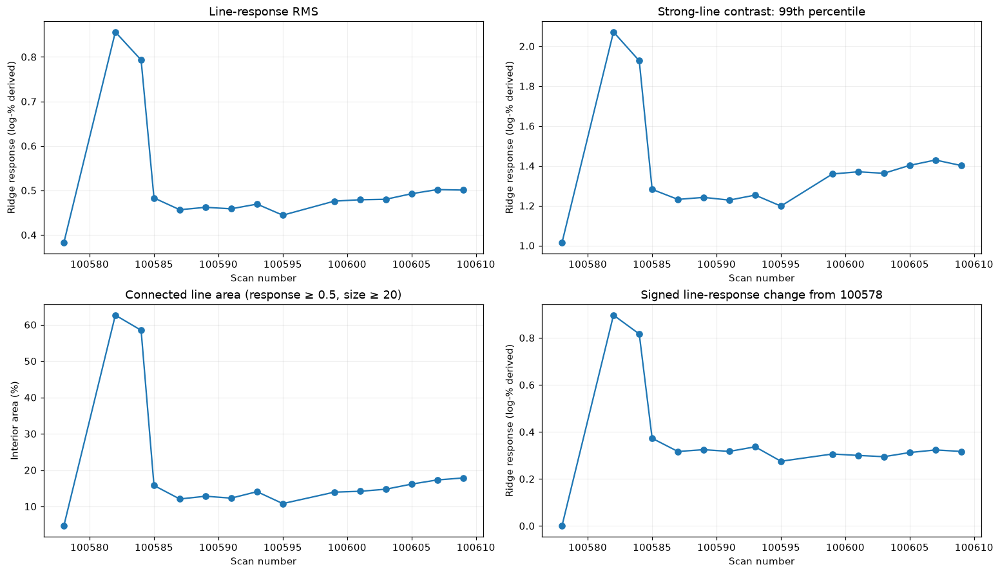

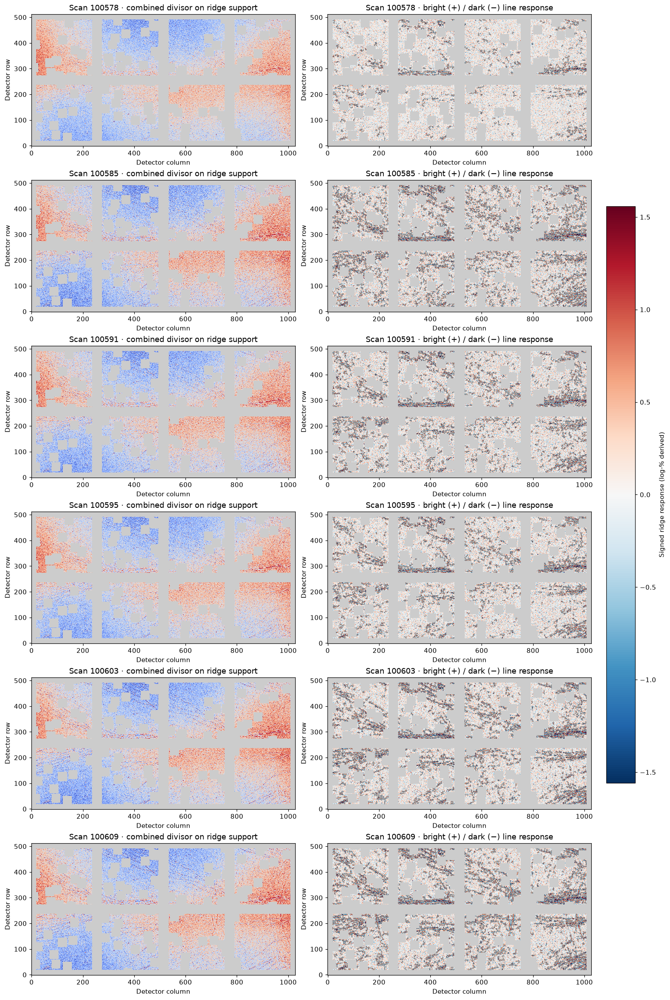

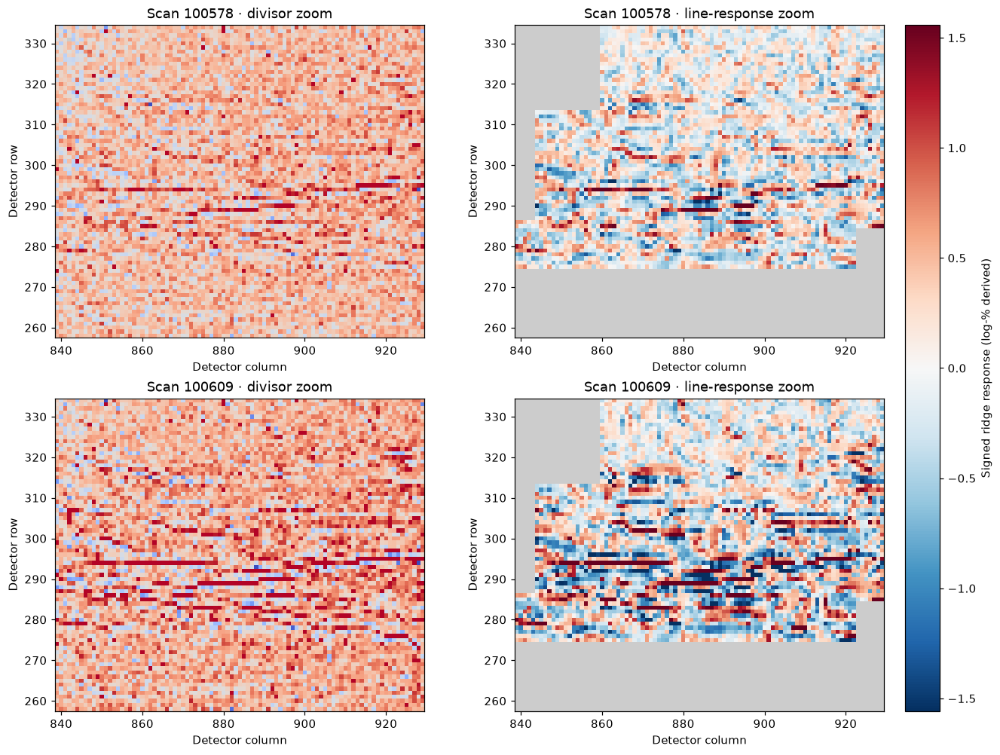

Inspect the zooms: do the responses follow the wavy lines rather than speckle?
If speckle dominates, raise the smallest RIDGE_SIGMAS_PIXELS value (e.g. (2, 4, 6)),
and adjust the shared threshold. Grey areas are excluded, not absence of lines.


In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
for field, title, ax in zip(
    ('ridge_rms', 'ridge_p99', 'connected_ridge_area_percent', 'signed_ridge_change_rms'),
    ('Line-response RMS', 'Strong-line contrast: 99th percentile',
     f'Connected line area (response ≥ {RIDGE_THRESHOLD:g}, size ≥ {RIDGE_MIN_COMPONENT_PIXELS})',
     f'Signed line-response change from {reference_scan}'), axes.flat):
    ax.plot(scans, ridge_trends[field], 'o-')
    ax.set(title=title, xlabel='Scan number',
           ylabel='Interior area (%)' if field == 'connected_ridge_area_percent' else 'Ridge response (log-% derived)')
    ax.grid(alpha=0.2)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
plt.show()

ridge_cmap = plt.get_cmap('RdBu_r').copy()
ridge_cmap.set_bad('0.8')
ridge_limit = max(float(np.percentile(np.abs(ridge_maps[:, ridge_support]), 99)), 1e-6)
fig, axes = plt.subplots(len(map_indices), 2, figsize=(14, 3.5 * len(map_indices)),
                         squeeze=False, constrained_layout=True)
for row, i in enumerate(map_indices):
    original = np.ma.array(records[i]['combined_divisor'], mask=~ridge_support)
    axes[row, 0].imshow(original, origin='lower', cmap=cmap, vmin=divisor_limits[0], vmax=divisor_limits[1],
                        interpolation='nearest')
    axes[row, 0].set_title(f'Scan {scans[i]} · combined divisor on ridge support')
    image = axes[row, 1].imshow(np.ma.array(ridge_maps[i], mask=~ridge_support), origin='lower',
                                cmap=ridge_cmap, vmin=-ridge_limit, vmax=ridge_limit, interpolation='nearest')
    if ridge_fragment_masks[i].any() and not ridge_fragment_masks[i].all():
        axes[row, 1].contour(ridge_fragment_masks[i], levels=[0.5], colors='black', linewidths=0.25, alpha=0.5)
    axes[row, 1].set_title(f'Scan {scans[i]} · bright (+) / dark (−) line response')
    for ax in axes[row]:
        ax.set(xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=axes[:, 1].tolist(), shrink=0.6, label='Signed ridge response (log-% derived)')
plt.show()

# Focus on the strongest line location in the final selected scan, not an isolated raw pixel.
ridge_last = len(scans) - 1
ridge_r, ridge_c = np.unravel_index(np.nanargmax(np.abs(ridge_maps[ridge_last])), sensor_ids.shape)
ridge_sensor = sensor_ids[ridge_r, ridge_c]
ridge_sr, ridge_sc = np.where(sensor_ids == ridge_sensor)
ridge_zoom = np.s_[max(int(ridge_sr.min()), ridge_r - 45):min(int(ridge_sr.max()) + 1, ridge_r + 46),
                    max(int(ridge_sc.min()), ridge_c - 45):min(int(ridge_sc.max()) + 1, ridge_c + 46)]
ridge_extent = (ridge_zoom[1].start - 0.5, ridge_zoom[1].stop - 0.5,
                ridge_zoom[0].start - 0.5, ridge_zoom[0].stop - 0.5)
fig, axes = plt.subplots(2, 2, figsize=(12, 9), constrained_layout=True)
for row, i in enumerate((reference_index, ridge_last)):
    axes[row, 0].imshow(np.ma.array(records[i]['combined_divisor'][ridge_zoom],
                                    mask=~common_valid[ridge_zoom]), origin='lower', extent=ridge_extent,
                         cmap=cmap, vmin=divisor_limits[0], vmax=divisor_limits[1], interpolation='nearest')
    image = axes[row, 1].imshow(np.ma.array(ridge_maps[i][ridge_zoom], mask=~ridge_support[ridge_zoom]),
                                origin='lower', extent=ridge_extent, cmap=ridge_cmap,
                                vmin=-ridge_limit, vmax=ridge_limit, interpolation='nearest')
    axes[row, 0].set_title(f'Scan {scans[i]} · divisor zoom')
    axes[row, 1].set_title(f'Scan {scans[i]} · line-response zoom')
    for ax in axes[row]:
        ax.set(xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=axes[:, 1].tolist(), label='Signed ridge response (log-% derived)')
plt.show()
print('Inspect the zooms: do the responses follow the wavy lines rather than speckle?')
print('If speckle dominates, raise the smallest RIDGE_SIGMAS_PIXELS value (e.g. (2, 4, 6)),')
print('and adjust the shared threshold. Grey areas are excluded, not absence of lines.')

In [10]:
# Focused checks: prefer a line to a round spot at equal peak height/width,
# retain both polarities, and ignore a multiplicative sensor offset.
_test_y, _test_x = np.mgrid[-64:65, -64:65]
_test_line = 5 * np.exp(-_test_y**2 / (2 * 2.0**2))
_test_spot = 5 * np.exp(-(_test_x**2 + _test_y**2) / (2 * 2.0**2))
_test_line_response = ridge_response_2d(_test_line, ridge_sigmas, RIDGE_BETA)
_test_spot_response = ridge_response_2d(_test_spot, ridge_sigmas, RIDGE_BETA)
assert _test_line_response[64, 64] > 5 * abs(_test_spot_response[64, 64])
np.testing.assert_allclose(ridge_response_2d(-_test_line, ridge_sigmas, RIDGE_BETA),
                           -_test_line_response, atol=1e-12)
_test_divisor = records[reference_index]['combined_divisor'].copy()
_test_divisor[sensor_ids == 0] *= 1.1
np.testing.assert_allclose(sensor_ridge_response(_test_divisor)[ridge_support],
                           ridge_maps[reference_index][ridge_support], atol=1e-10, rtol=1e-10)
assert np.isfinite(ridge_maps[:, ridge_support]).all()
assert np.all(ridge_fragment_masks[:, ~ridge_support] == 0)
print('Ridge checks passed: line preference, bright/dark symmetry, sensor-offset invariance, fixed support.')

Ridge checks passed: line preference, bright/dark symmetry, sensor-offset invariance, fixed support.


## Separate coherent line amplitude from unstructured variation

**Recommended comparison for lines that recur at the same detector coordinates:** define one template from an explicit set of other scans, then fit its signed amplitude in every scan. The default template uses 100599, 100603 and 100607; importantly it contains neither 100582 nor 100584. These are exploratory reference choices, not certified noise-free data. Template-building scans are marked separately because their scores are self-included, not independent validation.

A per-sensor difference of Gaussian smooths (1.5 and 6 pixels) removes pixel-scale speckle and broad offsets. A fixed line-region mask is selected once from the template ridge response. The signed least-squares amplitude is `sum(template × scan) / sum(template²)` on that mask, after removing each sensor's mean on the mask. It is 1 for the template, 0 for no matching pattern, and can be negative. **No absolute value, clipping, scan-dependent line selection or correlation normalization is applied to amplitude.** Thus independent zero-mean additive noise increases its scatter rather than systematically inflating its mean. The unexplained residual is reported separately, not counted as lines.

This measures **this template's recurring morphology**, not all possible lines: shifted/new branches can be missed, and stable non-line structure can contribute. Inspect the template and mask overlay before trusting it. Results depend on spatial scales and template selection. Common fixed support is used; mask-normalized smoothing never mixes sensors, and analysis excludes a kernel-sized margin around masks.

The saved calibration files have observation counts but **no per-pixel divisor uncertainty or raw-count sums**. Observation counts are not photon counts. We cannot establish Poisson error bars or prove counting statistics are the cause from these files alone. The following injection experiment tests susceptibility to independent log-space Gaussian noise only; it does not simulate Poisson counts, spatial correlations or the nonlinear calibration fit.

Template scans: (100599, 100603, 100607)
Fixed line support: 201,965; fixed template-selected pixels: 30,295
Amplitude is the primary matching-pattern measure; correlation decreases with added noise.


,template_training_scan,matched_line_amplitude,unmatched_rms_log_percent,template_correlation
scan,,,,
100578,False,0.6862,0.1070,0.9242
100582,False,0.4486,0.5242,0.3074
100584,False,0.5741,0.4808,0.4110
100585,False,0.8255,0.1780,0.8683
100587,False,0.8152,0.1432,0.9066
100589,False,0.8239,0.1478,0.9033
100591,False,0.8206,0.1431,0.9079
100593,False,0.8290,0.1491,0.9027
100595,False,0.8204,0.1224,0.9300


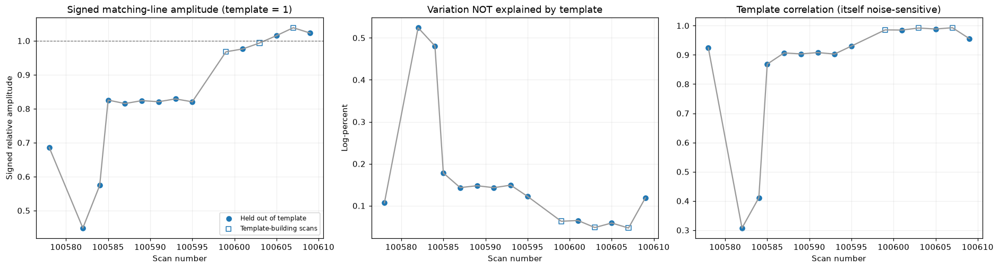

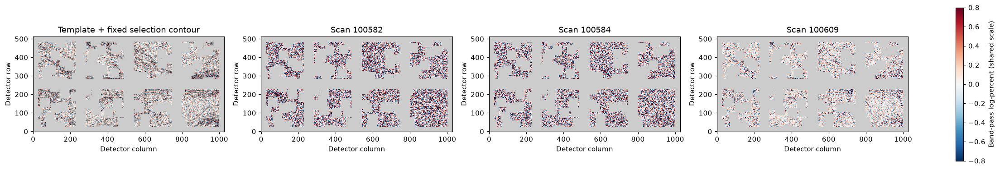

In [11]:
TEMPLATE_SCANS = (100599, 100603, 100607)  # Explicit training scans; targets 100582/100584 are held out.
LINE_BAND_SIGMAS = (1.5, 6.0)
TEMPLATE_LINE_PERCENTILE = 85.0  # Select the strongest 15% of template ridge responses, once.

if not TEMPLATE_SCANS or any(scan not in files.index for scan in TEMPLATE_SCANS):
    raise ValueError('Choose TEMPLATE_SCANS from the selected scans; do not include the scans being tested.')
if len(set(TEMPLATE_SCANS)) != len(TEMPLATE_SCANS):
    raise ValueError('TEMPLATE_SCANS must not contain duplicates.')
if (len(LINE_BAND_SIGMAS) != 2 or not np.all(np.isfinite(LINE_BAND_SIGMAS))
        or not 0 < LINE_BAND_SIGMAS[0] < LINE_BAND_SIGMAS[1]):
    raise ValueError('LINE_BAND_SIGMAS must be two increasing positive scales.')
if not 0 < TEMPLATE_LINE_PERCENTILE < 100:
    raise ValueError('TEMPLATE_LINE_PERCENTILE must be between 0 and 100.')
line_margin = int(np.ceil(4 * max(LINE_BAND_SIGMAS))) + 1
line_support = np.zeros_like(common_valid)
for sensor, region, valid in ridge_regions:
    line_support[region] |= minimum_filter(valid.astype(np.uint8), size=2 * line_margin + 1,
                                           mode='constant', cval=0).astype(bool)
line_support &= ridge_support
if not line_support.any():
    raise ValueError('No fixed line support remains. Reduce smoothing scales or narrow scan selection.')


def line_bandpass(log_percent_map):
    band = np.full(sensor_ids.shape, np.nan)
    for sensor, region, valid in ridge_regions:
        values = np.where(valid, log_percent_map[region], 0.0)
        smooths = []
        for sigma in LINE_BAND_SIGMAS:
            weight = gaussian_filter(valid.astype(float), sigma, mode='constant', truncate=4.0)
            smooths.append(gaussian_filter(values, sigma, mode='constant', truncate=4.0)
                           / np.maximum(weight, 1e-15))
        interior = line_support[region] & (sensor_ids[region] == sensor)
        band[region][interior] = (smooths[0] - smooths[1])[interior]
    return band


line_log_maps = np.stack([100 * np.log(np.where(common_valid, r['combined_divisor'], 1.0)) for r in records])
line_band_maps = np.stack([line_bandpass(values) for values in line_log_maps])
template_indices = [int(np.flatnonzero(scans == scan)[0]) for scan in TEMPLATE_SCANS]
line_template_log = np.mean(line_log_maps[template_indices], axis=0)
line_template_band = line_bandpass(line_template_log)
line_template_ridge = sensor_ridge_response(np.exp(line_template_log / 100))
line_selection_threshold = np.percentile(np.abs(line_template_ridge[line_support]), TEMPLATE_LINE_PERCENTILE)
if not np.isfinite(line_selection_threshold) or line_selection_threshold <= 0:
    raise ValueError('Template has no measurable ridge structure on the chosen support.')
line_template_mask = line_support & (np.abs(line_template_ridge) >= line_selection_threshold)


def line_vector(band):
    # Removing sensor means prevents offsets on the selected line mask affecting the fit.
    parts = []
    for sensor in range(8):
        values = band[line_template_mask & (sensor_ids == sensor)]
        if values.size:
            parts.append(values - values.mean())
    return np.concatenate(parts)


line_template_vector = line_vector(line_template_band)
line_template_energy = float(line_template_vector @ line_template_vector)
if line_template_energy <= 1e-12:
    raise ValueError('Template has negligible band-pass energy.')


def matched_line_metrics(band):
    values = line_vector(band)
    amplitude = float(line_template_vector @ values / line_template_energy)
    residual = values - amplitude * line_template_vector
    correlation = float(line_template_vector @ values / np.sqrt(line_template_energy * (values @ values))) if values @ values > 0 else np.nan
    return amplitude, float(np.sqrt(np.mean(residual**2))), correlation


matched_rows = []
for i, scan in enumerate(scans):
    amplitude, residual, correlation = matched_line_metrics(line_band_maps[i])
    matched_rows.append({'scan': scan, 'template_training_scan': int(scan) in TEMPLATE_SCANS,
                         'matched_line_amplitude': amplitude, 'unmatched_rms_log_percent': residual,
                         'template_correlation': correlation})
matched_lines = pd.DataFrame(matched_rows).set_index('scan')
print('Template scans:', TEMPLATE_SCANS)
print(f'Fixed line support: {line_support.sum():,}; fixed template-selected pixels: {line_template_mask.sum():,}')
print('Amplitude is the primary matching-pattern measure; correlation decreases with added noise.')
display(matched_lines.round(4))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for ax, field, title in zip(axes,
    ('matched_line_amplitude', 'unmatched_rms_log_percent', 'template_correlation'),
    ('Signed matching-line amplitude (template = 1)', 'Variation NOT explained by template',
     'Template correlation (itself noise-sensitive)')):
    ax.plot(scans, matched_lines[field], '-', color='0.6')
    for training, marker, label_text in ((False, 'o', 'Held out of template'), (True, 's', 'Template-building scans')):
        selected = matched_lines['template_training_scan'].to_numpy() == training
        ax.scatter(scans[selected], matched_lines.loc[selected, field], marker=marker,
                   facecolors='none' if training else 'tab:blue', edgecolors='tab:blue', label=label_text)
    ax.set(title=title, xlabel='Scan number')
    ax.grid(alpha=0.2)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
axes[0].axhline(1, color='0.4', ls='--', lw=0.8)
axes[0].set_ylabel('Signed relative amplitude')
axes[0].legend(fontsize=8)
axes[1].set_ylabel('Log-percent')
plt.show()

line_compare_scans = list(dict.fromkeys([scan for scan in (100582, 100584, int(scans[-1])) if scan in files.index]))
line_plot_limit = max(float(np.percentile(np.abs(line_template_band[line_support]), 99)), 1e-6)
fig, axes = plt.subplots(1, 1 + len(line_compare_scans), figsize=(5 * (1 + len(line_compare_scans)), 4.5),
                         squeeze=False, constrained_layout=True)
line_plot_maps = [line_template_band] + [line_band_maps[int(np.flatnonzero(scans == scan)[0])] for scan in line_compare_scans]
for ax, values, title in zip(axes[0], line_plot_maps, ['Template + fixed selection contour'] + [f'Scan {scan}' for scan in line_compare_scans]):
    image = ax.imshow(np.ma.array(values, mask=~line_support), origin='lower', cmap=ridge_cmap,
                       vmin=-line_plot_limit, vmax=line_plot_limit, interpolation='nearest')
    ax.set(title=title, xlabel='Detector column', ylabel='Detector row')
axes[0, 0].contour(line_template_mask, levels=[0.5], colors='black', linewidths=0.25, alpha=0.5)
fig.colorbar(image, ax=axes[0].tolist(), shrink=0.7, label='Band-pass log-percent (shared scale)')
plt.show()

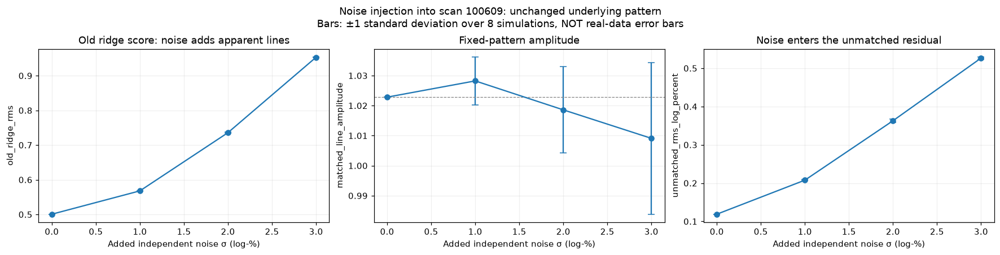

,old_ridge_rms,matched_line_amplitude,unmatched_rms_log_percent
added_sigma_log_percent,,,
0.0,0.5007,1.0228,0.1188
1.0,0.5679,1.0282,0.2077
2.0,0.7358,1.0186,0.3629
3.0,0.9530,1.0091,0.5265


Checks passed: template amplitude = 1, finite fits, fixed support, signed-noise cancellation.
This demonstrates metric bias under independent additive noise; it does not identify the actual noise source.


In [12]:
# A fixed underlying divisor with increasing independent noise: no new physical lines.
# These are illustrative log-space noise levels, NOT estimated Poisson uncertainties.
NOISE_TEST_BASE_SCAN = 100609
NOISE_TEST_SIGMAS = (0.0, 1.0, 2.0, 3.0)
NOISE_TEST_REPEATS = 8
if NOISE_TEST_BASE_SCAN not in files.index:
    raise ValueError('Choose NOISE_TEST_BASE_SCAN from the selected scans.')
if NOISE_TEST_BASE_SCAN in TEMPLATE_SCANS:
    raise ValueError('Use a held-out base scan for the noise-injection test.')
if (not np.all(np.isfinite(NOISE_TEST_SIGMAS)) or np.any(np.asarray(NOISE_TEST_SIGMAS) < 0)
        or not isinstance(NOISE_TEST_REPEATS, (int, np.integer)) or NOISE_TEST_REPEATS < 2):
    raise ValueError('Use finite nonnegative noise levels and at least two repetitions.')
noise_base_index = int(np.flatnonzero(scans == NOISE_TEST_BASE_SCAN)[0])
noise_rng = np.random.default_rng(45166)
noise_test_rows = []
for noise_sigma in NOISE_TEST_SIGMAS:
    for repeat in range(NOISE_TEST_REPEATS):
        noisy_log = line_log_maps[noise_base_index] + noise_rng.normal(0, noise_sigma, sensor_ids.shape)
        noisy_divisor = np.exp(noisy_log / 100)
        noisy_ridges = sensor_ridge_response(noisy_divisor)
        amplitude, residual, _ = matched_line_metrics(line_bandpass(noisy_log))
        noise_test_rows.append({'added_sigma_log_percent': noise_sigma, 'repeat': repeat,
                                'old_ridge_rms': np.sqrt(np.mean(noisy_ridges[ridge_support]**2)),
                                'matched_line_amplitude': amplitude,
                                'unmatched_rms_log_percent': residual})
noise_test = pd.DataFrame(noise_test_rows)
noise_group = noise_test.groupby('added_sigma_log_percent')
noise_means = noise_group.mean(numeric_only=True)
noise_stds = noise_group.std(numeric_only=True)
fig, axes = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, field, title in zip(axes,
    ('old_ridge_rms', 'matched_line_amplitude', 'unmatched_rms_log_percent'),
    ('Old ridge score: noise adds apparent lines', 'Fixed-pattern amplitude', 'Noise enters the unmatched residual')):
    ax.errorbar(noise_means.index, noise_means[field], yerr=noise_stds[field], fmt='o-', capsize=4)
    ax.set(title=title, xlabel='Added independent noise σ (log-%)', ylabel=field)
    ax.grid(alpha=0.2)
axes[1].axhline(matched_lines.loc[NOISE_TEST_BASE_SCAN, 'matched_line_amplitude'], color='0.5', ls='--', lw=0.8)
fig.suptitle(f'Noise injection into scan {NOISE_TEST_BASE_SCAN}: unchanged underlying pattern\n'
             f'Bars: ±1 standard deviation over {NOISE_TEST_REPEATS} simulations, NOT real-data error bars')
plt.show()
display(noise_means.drop(columns='repeat').round(4))

# Exact linearity check: an injected noise realization and its negative cancel in amplitude.
check_noise = noise_rng.normal(0, 3.0, sensor_ids.shape)
amp_plus = matched_line_metrics(line_bandpass(line_log_maps[noise_base_index] + check_noise))[0]
amp_minus = matched_line_metrics(line_bandpass(line_log_maps[noise_base_index] - check_noise))[0]
np.testing.assert_allclose(0.5 * (amp_plus + amp_minus),
                           matched_lines.loc[NOISE_TEST_BASE_SCAN, 'matched_line_amplitude'], atol=1e-10)
np.testing.assert_allclose(matched_line_metrics(line_template_band)[0], 1.0, atol=1e-12)
assert np.isfinite(matched_lines['matched_line_amplitude']).all()
assert np.all(line_template_mask <= line_support)
print('Checks passed: template amplitude = 1, finite fits, fixed support, signed-noise cancellation.')
print('This demonstrates metric bias under independent additive noise; it does not identify the actual noise source.')

## Cross-correlation against the last scan (assumed worst)

The highest selected scan number is the reference here, independently of the earlier reference/template settings. **“Worst” is a working assumption, not inferred by this analysis.** Comparing two maps is cross-correlation; the final scan compared with itself is its autocorrelation.

We compare (1) log combined divisors with sensor offsets removed and (2) the earlier line-scale band-pass maps. No ridge threshold or template-feature selection is used: **every pixel on the fixed line support** enters both comparisons. This avoids mistaking gain offsets or mask zeros for agreement. Log-space correlation emphasizes relative changes rather than the large constant divisor baseline near 1.

At each integer lag, only valid overlapping pixels **within the same sensor** are paired. Means and variances are recalculated on each overlap, separately per sensor, then pooled. FFT correlation is linear, not circular: no wraparound and no crossing sensor boundaries. Lags with less than 80% of the zero-lag overlap are excluded by default.

- **Zero-lag correlation:** normalized pattern similarity at the original detector coordinates; 1 means a positive linear match, not necessarily equal strength.
- **Zero-lag amplitude:** regression coefficient of the scan onto the last scan, with sensor intercepts; 1 matches the last scan's amplitude. Noise in the reference can attenuate this estimate. A weaker/new/shifted pattern is not necessarily detector improvement.
- **Peak correlation and lag:** strongest positive match in the chosen lag window; searching lags introduces selection bias, so this is diagnostic, not a significance test. The lag is the translation to apply to the current scan to align with the reference (positive row = upwards on these origin-lower plots).

Independent noise lowers normalized correlation. These numbers are descriptive and not noise-corrected; the last scan's self-correlation and amplitude equal 1 by construction. The raw-divisor comparison also includes stable non-line pixel response; the band-pass comparison is more relevant to the wavy structures. All results depend on the chosen spatial scales and support.

In [14]:
from scipy.signal import correlate

XCORR_MAX_LAG_PIXELS = 20
XCORR_MIN_OVERLAP_FRACTION = 0.8
if not isinstance(XCORR_MAX_LAG_PIXELS, (int, np.integer)) or XCORR_MAX_LAG_PIXELS < 1:
    raise ValueError('XCORR_MAX_LAG_PIXELS must be a positive integer.')
if not 0 < XCORR_MIN_OVERLAP_FRACTION <= 1:
    raise ValueError('XCORR_MIN_OVERLAP_FRACTION must be in (0, 1].')
xcorr_reference_index = len(scans) - 1
xcorr_reference_scan = int(scans[xcorr_reference_index])
xcorr_lags = np.arange(-XCORR_MAX_LAG_PIXELS, XCORR_MAX_LAG_PIXELS + 1)
xcorr_zero = XCORR_MAX_LAG_PIXELS


def overlap_crosscorrelation(reference, current, support, ids, max_lag, minimum_fraction=0.8):
    """Overlap-centred pooled Pearson correlation; lag translates current onto reference."""
    shape = (2 * max_lag + 1, 2 * max_lag + 1)
    covariance, reference_energy, current_energy, overlap = [np.zeros(shape) for _ in range(4)]
    for sensor in np.unique(ids[support]):
        rr, cc = np.where(ids == sensor)
        region = np.s_[rr.min():rr.max() + 1, cc.min():cc.max() + 1]
        mask = support[region] & (ids[region] == sensor)
        if not mask.any():
            continue
        if min(mask.shape) <= max_lag:
            raise ValueError('Lag window exceeds a sensor dimension.')
        weight = mask.astype(float)
        # Precentre for numerical stability; lag-specific means are removed below.
        ref = np.where(mask, reference[region] - reference[region][mask].mean(), 0.0)
        cur = np.where(mask, current[region] - current[region][mask].mean(), 0.0)
        if not np.isfinite(ref).all() or not np.isfinite(cur).all():
            raise ValueError('Nonfinite values on cross-correlation support.')

        def local_corr(a, b):
            full = correlate(a, b, mode='full', method='fft')
            cy, cx = np.array(mask.shape) - 1
            return full[cy - max_lag:cy + max_lag + 1, cx - max_lag:cx + max_lag + 1]

        n = np.maximum(np.rint(local_corr(weight, weight)), 0)
        denominator = np.maximum(n, 1)
        sum_ref, sum_cur = local_corr(ref, weight), local_corr(weight, cur)
        usable = n > 1
        covariance += np.where(usable, local_corr(ref, cur) - sum_ref * sum_cur / denominator, 0)
        reference_energy += np.where(usable, np.maximum(local_corr(ref**2, weight) - sum_ref**2 / denominator, 0), 0)
        current_energy += np.where(usable, np.maximum(local_corr(weight, cur**2) - sum_cur**2 / denominator, 0), 0)
        overlap += np.where(usable, n, 0)
    valid = ((overlap >= minimum_fraction * overlap[max_lag, max_lag])
             & (reference_energy > 1e-12) & (current_energy > 1e-12))
    correlation = np.full(shape, np.nan)
    correlation[valid] = np.clip(covariance[valid] / np.sqrt(reference_energy[valid] * current_energy[valid]), -1, 1)
    slope = np.full(shape, np.nan)
    slope[valid] = covariance[valid] / reference_energy[valid]
    return correlation, slope, overlap


xcorr_maps, xcorr_rows = {}, []
for kind, stack in (('log_divisor', line_log_maps), ('line_bandpass', line_band_maps)):
    maps = []
    for i, scan in enumerate(scans):
        correlation, slopes, overlap = overlap_crosscorrelation(
            stack[xcorr_reference_index], stack[i], line_support, sensor_ids,
            XCORR_MAX_LAG_PIXELS, XCORR_MIN_OVERLAP_FRACTION)
        if not np.isfinite(correlation).any():
            raise ValueError(f'No valid cross-correlation for scan {scan}.')
        peak = np.unravel_index(np.nanargmax(correlation), correlation.shape)
        xcorr_rows.append({'scan': scan, 'map_kind': kind,
                           'zero_lag_correlation': correlation[xcorr_zero, xcorr_zero],
                           'zero_lag_amplitude': slopes[xcorr_zero, xcorr_zero],
                           'peak_correlation': correlation[peak],
                           'align_row_shift': int(xcorr_lags[peak[0]]),
                           'align_column_shift': int(xcorr_lags[peak[1]]),
                           'peak_on_search_boundary': bool(0 in peak or 2 * XCORR_MAX_LAG_PIXELS in peak),
                           'zero_lag_pairs': int(overlap[xcorr_zero, xcorr_zero])})
        maps.append(correlation)
    xcorr_maps[kind] = np.stack(maps)
xcorr_table = pd.DataFrame(xcorr_rows).set_index(['map_kind', 'scan'])
print(f'Last-scan reference (assumed worst): {xcorr_reference_scan}; lags ±{XCORR_MAX_LAG_PIXELS} pixels')
display(xcorr_table.round(4))

Last-scan reference (assumed worst): 100609; lags ±20 pixels


zero_lag_correlation  zero_lag_amplitude  \
map_kind      scan                                               
log_divisor   100578                0.9120              0.7720   
              100582                0.3153              0.5051   
              100584                0.3868              0.5795   
              100585                0.8408              0.8385   
              100587                0.8820              0.8340   
              100589                0.8793              0.8403   
              100591                0.8858              0.8409   
              100593                0.8773              0.8487   
              100595                0.9161              0.8432   
              100599                0.9533              0.9363   
              100601                0.9649              0.9442   
              100603                0.9733              0.9521   
              100605                0.9740              0.9704   
              100607                0.9755              0.9871   
              100609                1.0000              1.0000   
line_bandpass 100578                0.8273              0.5922   
              100582                0.1771              0.3061   
              100584                0.2509              0.4036   
              100585                0.7230              0.6737   
              100587                0.7823              0.6788   
              100589                0.7783              0.6846   
              100591                0.7872              0.6880   
              100593                0.7760              0.6924   
              100595                0.8414              0.7083   
              100599                0.8938              0.7978   
              100601                0.9085              0.8199   
              100603                0.9148              0.8342   
              100605                0.9162              0.8560   
              100607                0.9175              0.8708   
              100609                1.0000              1.0000   

                      peak_correlation  align_row_shift  align_column_shift  \
map_kind      scan                                                            
log_divisor   100578            0.9120                0                   0   
              100582            0.3153                0                   0   
              100584            0.3868                0                   0   
              100585            0.8408                0                   0   
              100587            0.8820                0                   0   
              100589            0.8793                0                   0   
              100591            0.8858                0                   0   
              100593            0.8773                0                   0   
              100595            0.9161                0                   0   
              100599            0.9533                0                   0   
              100601            0.9649                0                   0   
              100603            0.9733                0                   0   
              100605            0.9740                0                   0   
              100607            0.9755                0                   0   
              100609            1.0000                0                   0   
line_bandpass 100578            0.8273                0                   0   
              100582            0.1771                0                   0   
              100584            0.2509                0                   0   
              100585            0.7230                0                   0   
              100587            0.7823                0                   0   
              100589            0.7783                0                   0   
              100591            0.7872                0                   0   
             

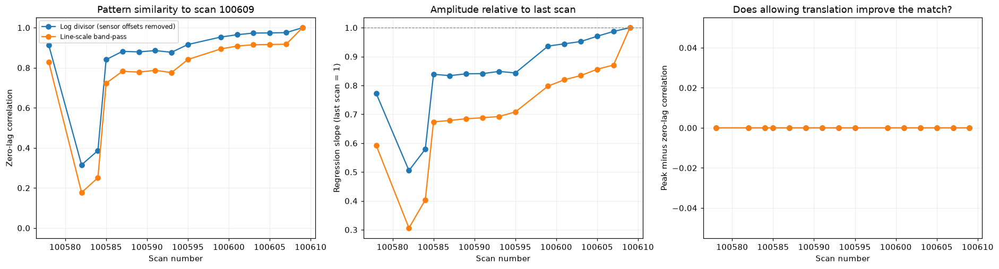

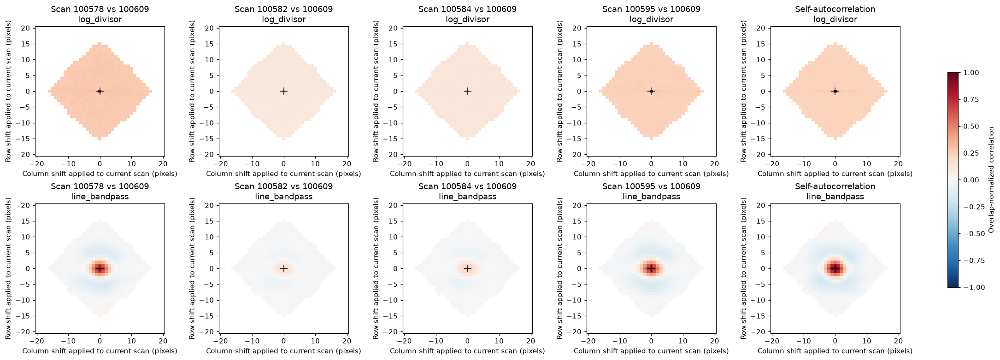

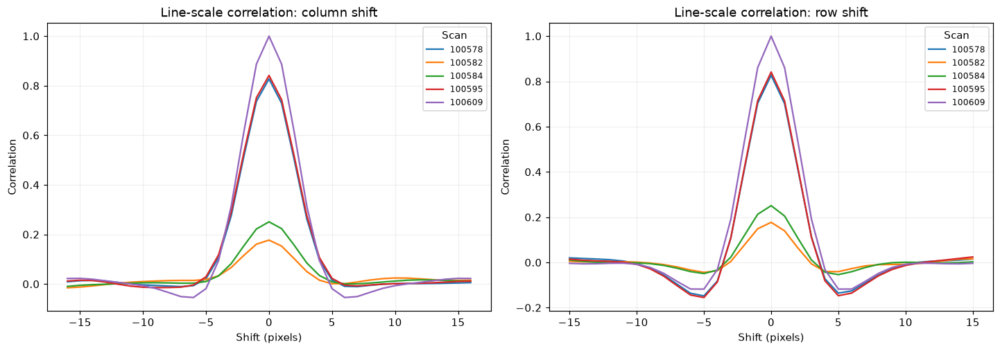

Extended combined results are available as trend_table_with_xcorr; no calibration files changed.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for kind, label_text in (('log_divisor', 'Log divisor (sensor offsets removed)'),
                          ('line_bandpass', 'Line-scale band-pass')):
    table = xcorr_table.loc[kind]
    axes[0].plot(scans, table['zero_lag_correlation'], 'o-', label=label_text)
    axes[1].plot(scans, table['zero_lag_amplitude'], 'o-', label=label_text)
    axes[2].plot(scans, table['peak_correlation'] - table['zero_lag_correlation'], 'o-', label=label_text)
axes[0].set(title=f'Pattern similarity to scan {xcorr_reference_scan}', ylabel='Zero-lag correlation', ylim=(-0.05, 1.05))
axes[1].set(title='Amplitude relative to last scan', ylabel='Regression slope (last scan = 1)')
axes[1].axhline(1, color='0.5', ls='--', lw=0.8)
axes[2].set(title='Does allowing translation improve the match?', ylabel='Peak minus zero-lag correlation')
axes[0].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel('Scan number')
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.grid(alpha=0.2)
plt.show()

# Always include the two disputed scans when available, plus early/intermediate/last examples.
xcorr_show_scans = list(dict.fromkeys([s for s in (int(scans[0]), 100582, 100584, 100595,
                                                  xcorr_reference_scan) if s in files.index]))
fig, axes = plt.subplots(2, len(xcorr_show_scans), figsize=(4 * len(xcorr_show_scans), 7),
                         squeeze=False, constrained_layout=True)
lag_extent = (-XCORR_MAX_LAG_PIXELS - 0.5, XCORR_MAX_LAG_PIXELS + 0.5,
               -XCORR_MAX_LAG_PIXELS - 0.5, XCORR_MAX_LAG_PIXELS + 0.5)
for row, kind in enumerate(('log_divisor', 'line_bandpass')):
    for col, scan in enumerate(xcorr_show_scans):
        i = int(np.flatnonzero(scans == scan)[0])
        ax = axes[row, col]
        image = ax.imshow(xcorr_maps[kind][i], origin='lower', extent=lag_extent,
                           cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
        values = xcorr_table.loc[(kind, scan)]
        ax.plot(values['align_column_shift'], values['align_row_shift'], '+', color='black', ms=10)
        title = 'Self-autocorrelation' if scan == xcorr_reference_scan else f'Scan {scan} vs {xcorr_reference_scan}'
        ax.set(title=f'{title}\n{kind}', xlabel='Column shift applied to current scan (pixels)',
               ylabel='Row shift applied to current scan (pixels)')
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.7, label='Overlap-normalized correlation')
plt.show()

# Horizontal/vertical sections reveal broad spatial agreement versus a narrow pixel-scale spike.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for scan in xcorr_show_scans:
    i = int(np.flatnonzero(scans == scan)[0])
    values = xcorr_maps['line_bandpass'][i]
    axes[0].plot(xcorr_lags, values[xcorr_zero, :], label=str(scan))
    axes[1].plot(xcorr_lags, values[:, xcorr_zero], label=str(scan))
for ax, direction in zip(axes, ('column', 'row')):
    ax.set(title=f'Line-scale correlation: {direction} shift', xlabel='Shift (pixels)', ylabel='Correlation')
    ax.grid(alpha=0.2)
    ax.legend(title='Scan', fontsize=8)
plt.show()
xcorr_wide = xcorr_table[['zero_lag_correlation', 'zero_lag_amplitude', 'peak_correlation',
                          'align_row_shift', 'align_column_shift']].unstack('map_kind')
xcorr_wide.columns = [f'lastscan_{kind}_{metric}' for metric, kind in xcorr_wide.columns]
trend_table_with_xcorr = summary.join(texture).join(sensor_gain_table).join(ridge_trends).join(matched_lines).join(xcorr_wide)
print('Extended combined results are available as trend_table_with_xcorr; no calibration files changed.')

In [16]:
# Validate normalization and lag direction rather than trusting the FFT convention.
for kind in ('log_divisor', 'line_bandpass'):
    self_row = xcorr_table.loc[(kind, xcorr_reference_scan)]
    np.testing.assert_allclose(self_row[['zero_lag_correlation', 'zero_lag_amplitude']].to_numpy(dtype=float), 1, atol=1e-10)
    assert self_row['align_row_shift'] == self_row['align_column_shift'] == 0

_check_rng = np.random.default_rng(610)
_check_ref = _check_rng.normal(size=(48, 56))
_check_current = np.roll(_check_ref, shift=(2, -3), axis=(0, 1))
_check_support = np.zeros(_check_ref.shape, dtype=bool)
_check_support[6:-6, 6:-6] = True
_check_ids = np.zeros(_check_ref.shape, dtype=int)
_check_corr, _, _ = overlap_crosscorrelation(_check_ref, _check_current, _check_support, _check_ids, 5, 0.5)
_check_peak = np.unravel_index(np.nanargmax(_check_corr), _check_corr.shape)
assert tuple(np.array(_check_peak) - 5) == (-2, 3)
np.testing.assert_allclose(_check_corr[_check_peak], 1, atol=1e-10)

# Direct per-sensor zero-lag calculation must agree with FFT pooling on real masked maps.
_check_cov = _check_ref_energy = _check_cur_energy = 0.0
for sensor in range(8):
    mask = line_support & (sensor_ids == sensor)
    if not mask.any():
        continue
    a = line_band_maps[xcorr_reference_index][mask]
    b = line_band_maps[0][mask]
    a, b = a - a.mean(), b - b.mean()
    _check_cov += a @ b
    _check_ref_energy += a @ a
    _check_cur_energy += b @ b
np.testing.assert_allclose(_check_cov / np.sqrt(_check_ref_energy * _check_cur_energy),
                           xcorr_table.loc[('line_bandpass', int(scans[0])), 'zero_lag_correlation'], atol=1e-10)
np.testing.assert_allclose(_check_cov / _check_ref_energy,
                           xcorr_table.loc[('line_bandpass', int(scans[0])), 'zero_lag_amplitude'], atol=1e-10)
print('Cross-correlation checks passed: self-normalization, known translation recovery, direct masked zero-lag agreement.')

Cross-correlation checks passed: self-normalization, known translation recovery, direct masked zero-lag agreement.


## Time and accumulated detector-count exposure

The y-axis remains the **zero-lag divisor-map amplitude relative to the last scan**; it is not an integrated-intensity or I0-normalized signal. Original NeXus and detector files are read-only. The next cells recover source paths, timestamps and an acquisition ledger including intervening scans, then sum recorded raw detector counts as an **exposure proxy, not absorbed dose**.

Cumulative exposure is relative to the beginning of the first selected calibration scan, not lifetime exposure. Unrecorded beam exposure, missing acquisitions, masked/saturated pixels and detector efficiency limit this proxy. Counts are not divided by I0 or by the fitted divisor: that would change the quantity being accumulated and introduce circularity. Time and accumulated counts can be strongly correlated; these plots alone cannot establish which causes the changes.

In [17]:
# Recover provenance from each saved calibration rather than assuming a visit directory.
SOURCE_DIRECTORY_OVERRIDE = None  # Optional Path if original files have moved.
source_scan_paths = {}
for scan, row in files.iterrows():
    with h5py.File(row.path, 'r') as calibration_file:
        source_path = Path(text(calibration_file.attrs['source_scan']))
    if SOURCE_DIRECTORY_OVERRIDE is not None:
        source_path = Path(SOURCE_DIRECTORY_OVERRIDE) / source_path.name
    if not source_path.is_file():
        raise FileNotFoundError(f'Source NeXus not found: {source_path}; set SOURCE_DIRECTORY_OVERRIDE.')
    source_scan_paths[int(scan)] = source_path
source_directories = sorted({p.parent for p in source_scan_paths.values()})
print('Source directories:', source_directories)
print('Source scan endpoints:', source_scan_paths[int(scans[0])], source_scan_paths[int(scans[-1])])

# Inspect actual metadata before selecting a counting method. No frame data is read here.
with h5py.File(source_scan_paths[int(scans[-1])], 'r') as exposure_probe:
    for key in ('entry/start_time', 'entry/end_time', 'entry/duration',
                'entry/plan_metadata/plan_name'):
        print(key, exposure_probe[key][()] if key in exposure_probe else 'not present')
    for key in ('entry/fastcs_eiger', 'entry/instrument/fastcs_eiger'):
        if key in exposure_probe:
            print(key, 'members:', list(exposure_probe[key]))
    exposure_summary_candidates = []
    def inspect_exposure_dataset(name, obj):
        if isinstance(obj, h5py.Dataset) and any(word in name.lower() for word in ('sum', 'total', 'count', 'time', 'exposure')):
            exposure_summary_candidates.append((name, obj.shape, str(obj.dtype)))
    exposure_probe.visititems(inspect_exposure_dataset)
    print('Potential summary/timing datasets:')
    display(pd.DataFrame(exposure_summary_candidates, columns=['dataset', 'shape', 'dtype']))


Source directories: [PosixPath('/dls/i15-1/data/2026/cm44163-4')]
Source scan endpoints: /dls/i15-1/data/2026/cm44163-4/i15-1-100578.nxs /dls/i15-1/data/2026/cm44163-4/i15-1-100609.nxs
entry/start_time b'2026-10-16T06:00:35.869'
entry/end_time b'2026-10-16T07:03:27.156'
entry/duration 3771286
entry/plan_metadata/plan_name b'data_collection'
entry/fastcs_eiger members: ['data', 'tth']
entry/instrument/fastcs_eiger members: ['data', 'local_name', 'pixel_mask']
Potential summary/timing datasets:


,dataset,shape,dtype
0,entry/diamond_scan/end_time,(),|S1024
1,entry/diamond_scan/scan_dead_time,(),int64
2,entry/diamond_scan/scan_dead_time_percent,(),float32
3,entry/diamond_scan/start_time,(),object
4,entry/instrument/i0/driver-averaging_time,(),float64
5,entry/instrument/i0/driver-sample_time,(),float64
6,entry/plan_metadata/auxiliary_scans/Air/time_p...,(),float64
7,entry/plan_metadata/auxiliary_scans/Empty Capi...,(),float64
8,entry/plan_metadata/auxiliary_scans/Standard S...,(),float64
9,entry/plan_metadata/experiment_definition/data...,(),int32


In [18]:
# Audit every intervening NeXus scan, not just files used to extract corrections.
# Naive NeXus timestamps are interpreted as Europe/London beamline wall-clock time.
SOURCE_TIMEZONE = 'Europe/London'
EXPOSURE_FIRST_SCAN = int(scans.min())  # Cumulative baseline; may be moved earlier explicitly.
EXPOSURE_LAST_SCAN = int(scans.max())
if EXPOSURE_FIRST_SCAN > int(scans.min()):
    raise ValueError('Exposure baseline cannot be later than the first selected calibration.')
source_name_pattern = re.compile(r'^(?P<prefix>.+)-(?P<scan>[0-9]+)[.]nxs$')
source_prefixes = {source_name_pattern.fullmatch(p.name)['prefix'] for p in source_scan_paths.values()}
if len(source_prefixes) != 1:
    raise ValueError('Select calibrations from one source run prefix before accumulating exposure.')
exposure_prefix = next(iter(source_prefixes))


def source_timestamp(handle, name):
    for key in (f'entry/{name}', f'entry/diamond_scan/{name}'):
        if key in handle:
            value = text(np.asarray(handle[key][()]).reshape(-1)[0]).strip()
            if value:
                stamp = pd.Timestamp(value)
                return stamp.tz_localize(SOURCE_TIMEZONE).tz_convert('UTC') if stamp.tzinfo is None else stamp.tz_convert('UTC')
    return pd.NaT


exposure_paths = {}
for directory in source_directories:
    for p in directory.glob(f'{exposure_prefix}-*.nxs'):
        match = source_name_pattern.fullmatch(p.name)
        if match and match['prefix'] == exposure_prefix:
            number = int(match['scan'])
            if EXPOSURE_FIRST_SCAN <= number <= EXPOSURE_LAST_SCAN:
                if number in exposure_paths and exposure_paths[number] != p:
                    raise ValueError(f'Duplicate source scan number {number}.')
                exposure_paths[number] = p
exposure_missing_numbers = sorted(set(range(EXPOSURE_FIRST_SCAN, EXPOSURE_LAST_SCAN + 1)) - set(exposure_paths))
exposure_rows = []
for number, p in sorted(exposure_paths.items()):
    ledger_row = {'scan': number, 'nexus_path': str(p), 'start_utc': pd.NaT, 'end_utc': pd.NaT,
                  'plan': '', 'dataset': '', 'frames': 0, 'shape': None, 'status': 'unknown',
                  'is_calibration_scan': number in source_scan_paths}
    try:
        with h5py.File(p, 'r') as source_file:
            ledger_row['start_utc'] = source_timestamp(source_file, 'start_time')
            ledger_row['end_utc'] = source_timestamp(source_file, 'end_time')
            if 'entry/plan_metadata/plan_name' in source_file:
                ledger_row['plan'] = text(source_file['entry/plan_metadata/plan_name'][()])
            for key in ('entry/fastcs_eiger/data', 'entry/instrument/fastcs_eiger/data'):
                if key in source_file:
                    ds = source_file[key]  # Follow original external/VDS links, including all frames.
                    if not isinstance(ds, h5py.Dataset) or ds.ndim != 3 or ds.shape[1:] != sensor_ids.shape:
                        raise ValueError(f'Unexpected detector shape at {key}: {getattr(ds, "shape", None)}')
                    ledger_row.update(dataset=key, frames=int(ds.shape[0]), shape=ds.shape, status='ready')
                    break
            if not ledger_row['dataset']:
                chunks = list(p.parent.glob(p.stem + '-fastcs_eiger_[0-9]*.h5'))
                if chunks or 'entry/fastcs_eiger' in source_file or 'entry/instrument/fastcs_eiger' in source_file:
                    raise ValueError('EIGER acquisition present but no usable NeXus-linked frame dataset.')
                ledger_row['status'] = 'no EIGER acquisition'
    except (OSError, KeyError, ValueError) as exc:
        ledger_row['status'] = 'ERROR: ' + str(exc)
    exposure_rows.append(ledger_row)
exposure_ledger = pd.DataFrame(exposure_rows).set_index('scan')
exposure_ledger['start_utc'] = pd.to_datetime(exposure_ledger['start_utc'], utc=True)
exposure_ledger['end_utc'] = pd.to_datetime(exposure_ledger['end_utc'], utc=True)
print('Missing scan numbers in interval:', exposure_missing_numbers or 'none')
print('Acquisition audit:', exposure_ledger['status'].value_counts().to_dict())
print('Raw detector frames to stream:', int(exposure_ledger['frames'].sum()))
print('Uncompressed uint32-equivalent data volume (GiB):',
      float(exposure_ledger['frames'].sum()) * sensor_ids.size * 4 / 2**30)
display(exposure_ledger.drop(columns=['nexus_path']))


Missing scan numbers in interval: none
Acquisition audit: {'ready': 32}
Raw detector frames to stream: 28311
Uncompressed uint32-equivalent data volume (GiB): 55.51091766357422


,start_utc,end_utc,plan,dataset,frames,shape,status,is_calibration_scan
scan,,,,,,,,
100578,2026-10-15 18:28:18.692000+00:00,2026-10-15 19:13:21.200000+00:00,data_collection,entry/fastcs_eiger/data,81,"(81, 512, 1028)",ready,True
100579,2026-10-15 19:21:25.825000+00:00,2026-10-15 19:28:49.622000+00:00,data_collection,entry/fastcs_eiger/data,31,"(31, 512, 1028)",ready,False
100580,2026-10-15 20:03:10.281000+00:00,2026-10-15 20:10:17.239000+00:00,data_collection,entry/fastcs_eiger/data,310,"(310, 512, 1028)",ready,False
100581,2026-10-15 20:11:58.714000+00:00,2026-10-15 20:12:57.203000+00:00,centre_sample,entry/fastcs_eiger/data,27,"(27, 512, 1028)",ready,False
100582,2026-10-15 20:13:11.601000+00:00,2026-10-15 20:20:12.821000+00:00,data_collection,entry/fastcs_eiger/data,310,"(310, 512, 1028)",ready,True
100583,2026-10-15 20:21:22.781000+00:00,2026-10-15 20:22:21.744000+00:00,centre_sample,entry/fastcs_eiger/data,27,"(27, 512, 1028)",ready,False
100584,2026-10-15 20:22:35.862000+00:00,2026-10-15 20:29:36.196000+00:00,data_collection,entry/fastcs_eiger/data,310,"(310, 512, 1028)",ready,True
100585,2026-10-15 20:35:23.749000+00:00,2026-10-15 20:42:28.820000+00:00,data_collection,entry/fastcs_eiger/data,31,"(31, 512, 1028)",ready,True
100586,2026-10-15 20:44:47.756000+00:00,2026-10-15 20:45:45.880000+00:00,centre_sample,entry/fastcs_eiger/data,27,"(27, 512, 1028)",ready,False


### Count definition and acquisition interval

Count totals include **all NeXus-linked EIGER acquisitions in the inclusive scan interval**, regardless of plan name or whether a calibration was extracted. A fixed union of the native detector masks over those acquisitions is excluded; fitted bad-pixel masks and divisor corrections are not used. Nonfinite, negative and ≥10⁷ raw pixel values are excluded and their number is reported. Thus the result is the **sum of valid recorded counts on a fixed detector area**, not a complete incident-fluence or absorbed-dose measurement. Spatially redistributed illumination can change local detector exposure even at equal totals.

The ledger has cumulative counts immediately **before and after** each scan. For a calibration plot, the marker is at the halfway count exposure and the horizontal bar spans before→after; this is an acquisition range, not an error bar or the count at the time midpoint. Time markers use the midpoint of the recorded start/end timestamps, with the scan interval shown. Actual intra-scan evolution is unresolved. Timestamps without an offset are assumed to be Europe/London local time and converted to UTC.

The first count pass may be I/O intensive (~56 GiB uncompressed equivalent for the initial selection). Reads use small batches; rerunning the counting cell in the same kernel reuses in-memory per-acquisition totals after checking source-file metadata and count settings. Nothing is written to the original data or calibration files. Missing scans or read errors stop the complete-cumulative calculation rather than being silently treated as zero.

In [20]:
import time
import hdf5plugin  # Registers compression filters; all source opens remain read-only.

COUNT_BATCH_FRAMES = 8
COUNT_SATURATION = 1e7
if not isinstance(COUNT_BATCH_FRAMES, (int, np.integer)) or COUNT_BATCH_FRAMES < 1:
    raise ValueError('COUNT_BATCH_FRAMES must be a positive integer.')
if not np.isfinite(COUNT_SATURATION) or COUNT_SATURATION <= 0:
    raise ValueError('COUNT_SATURATION must be finite and positive.')
if exposure_missing_numbers or exposure_ledger['status'].str.startswith('ERROR').any():
    raise ValueError('Resolve missing/error scans before cumulative counting.')
if exposure_ledger[['start_utc', 'end_utc']].isna().any().any():
    raise ValueError('Missing acquisition timestamps.')
if (exposure_ledger['end_utc'] < exposure_ledger['start_utc']).any():
    raise ValueError('End time precedes start time.')
exposure_ledger = exposure_ledger.sort_values('start_utc').copy()
if (exposure_ledger['start_utc'].iloc[1:].reset_index(drop=True)
        < exposure_ledger['end_utc'].iloc[:-1].reset_index(drop=True)).any():
    raise ValueError('Acquisition intervals overlap; inspect cumulative exposure ordering.')

count_fixed_mask = np.zeros(sensor_ids.shape, dtype=bool)
count_scalar_mask_metadata = []
for number, ledger_row in exposure_ledger.iterrows():
    p = Path(ledger_row['nexus_path'])
    found_mask = False
    with h5py.File(p, 'r') as source_file:
        key = 'entry/instrument/fastcs_eiger/pixel_mask'
        if key in source_file:
            native = np.asarray(source_file[key][()])
            if native.shape == count_fixed_mask.shape:
                count_fixed_mask |= native != 0
                found_mask = True
            elif native.ndim == 0 and native.dtype.kind in 'SUO':
                # This acquisition stores scalar metadata here, NOT the pixel array.
                count_scalar_mask_metadata.append((number, text(native.item())))
            else:
                raise ValueError(f'Unexpected NeXus mask shape {native.shape} for scan {number}.')
    meta_path = p.with_name(p.stem + '-fastcs_eiger_meta.h5')
    if meta_path.is_file():
        with h5py.File(meta_path, 'r') as meta_file:
            native = np.asarray(meta_file['mask'][()])
            if native.shape != count_fixed_mask.shape:
                raise ValueError(f'Metadata mask shape differs for scan {number}.')
            count_fixed_mask |= native != 0
            found_mask = True
    if not found_mask and ledger_row['frames'] > 0:
        raise ValueError(f'No actual native-mask array found for scan {number}.')
count_area = ~count_fixed_mask
if not count_area.any():
    raise ValueError('No unmasked detector pixels remain.')
count_mask_hash = hashlib.sha256(count_fixed_mask.tobytes()).hexdigest()
if '_exposure_count_cache' not in globals():
    _exposure_count_cache = {}
print(f'Fixed counted area: {count_area.sum():,} pixels; excluded: {count_fixed_mask.sum():,}')
if count_scalar_mask_metadata:
    print('Scalar NeXus mask metadata ignored in favour of actual companion mask arrays; example:', count_scalar_mask_metadata[0])
count_start = time.perf_counter()
count_results = []
for number, ledger_row in exposure_ledger.iterrows():
    p = Path(ledger_row['nexus_path'])
    dependencies = sorted(set([p] + list(p.parent.glob(p.stem + '-fastcs_eiger*.h5'))))
    signature = tuple((str(dep.resolve()), dep.stat().st_size, dep.stat().st_mtime_ns) for dep in dependencies)
    key = (signature, ledger_row['dataset'], count_mask_hash, float(COUNT_SATURATION))
    cached = key in _exposure_count_cache
    if not cached:
        frame_totals, invalid_observations = [], 0
        if ledger_row['status'] == 'ready':
            with h5py.File(p, 'r') as source_file:
                data = source_file[ledger_row['dataset']]
                if data.shape != ledger_row['shape']:
                    raise ValueError(f'Detector shape changed for scan {number}.')
                if data.is_virtual:
                    for virtual in data.virtual_sources():
                        filename = text(virtual.file_name)
                        target = Path(filename)
                        if filename != '.':
                            target = target if target.is_absolute() else Path(data.file.filename).parent / target
                            if not target.is_file():
                                raise FileNotFoundError(f'Missing VDS constituent: {target}')
                for first in range(0, data.shape[0], COUNT_BATCH_FRAMES):
                    block = np.asarray(data[first:first + COUNT_BATCH_FRAMES])
                    good = count_area[None, :, :] & np.isfinite(block) & (block >= 0) & (block < COUNT_SATURATION)
                    invalid_observations += int(np.count_nonzero(count_area[None, :, :] & ~good))
                    frame_totals.extend(np.sum(block, axis=(1, 2), where=good, dtype=np.float64).tolist())
        frame_totals = np.asarray(frame_totals, dtype=float)
        if len(frame_totals) != int(ledger_row['frames']) or not np.all(np.isfinite(frame_totals) & (frame_totals >= 0)):
            raise ValueError(f'Invalid count totals for scan {number}.')
        _exposure_count_cache[key] = (frame_totals, invalid_observations)
    frame_totals, invalid_observations = _exposure_count_cache[key]
    total = float(frame_totals.sum())
    count_results.append({'scan': number, 'valid_raw_counts': total,
                          'invalid_unmasked_pixel_observations': invalid_observations,
                          'counted_pixel_observations': int(ledger_row['frames']) * int(count_area.sum()) - invalid_observations})
    print(f'{number}: {len(frame_totals):,} frames; {total:,.0f} counts; {invalid_observations:,} rejected values'
          + (' [memory cache]' if cached else ''), flush=True)
count_totals = pd.DataFrame(count_results).set_index('scan')
exposure_ledger = exposure_ledger.drop(columns=count_totals.columns, errors='ignore').join(count_totals)
exposure_ledger['cumulative_counts_after'] = exposure_ledger['valid_raw_counts'].cumsum()
exposure_ledger['cumulative_counts_before'] = exposure_ledger['cumulative_counts_after'] - exposure_ledger['valid_raw_counts']
exposure_ledger['cumulative_counts_half_exposure'] = 0.5 * (exposure_ledger['cumulative_counts_before'] + exposure_ledger['cumulative_counts_after'])
exposure_ledger['midpoint_utc'] = exposure_ledger['start_utc'] + (exposure_ledger['end_utc'] - exposure_ledger['start_utc']) / 2
exposure_origin = exposure_ledger['start_utc'].iloc[0]
exposure_ledger['elapsed_midpoint_hours'] = (exposure_ledger['midpoint_utc'] - exposure_origin).dt.total_seconds() / 3600
assert np.all(np.diff(exposure_ledger['cumulative_counts_after']) >= 0)
np.testing.assert_allclose(exposure_ledger['cumulative_counts_after'].iloc[-1], exposure_ledger['valid_raw_counts'].sum())
print(f'Count pass elapsed: {time.perf_counter() - count_start:.1f} s; total recorded-count proxy: '
      f'{exposure_ledger["valid_raw_counts"].sum():,.0f}')
display(exposure_ledger[['plan', 'frames', 'valid_raw_counts', 'invalid_unmasked_pixel_observations',
                          'cumulative_counts_before', 'cumulative_counts_after', 'is_calibration_scan']])

Fixed counted area: 525,279 pixels; excluded: 1,057
Scalar NeXus mask metadata ignored in favour of actual companion mask arrays; example: (100578, '/dls/i15-1/data/2026/cm44163-4/i15-1-100578-fastcs_eiger_meta.h5//mask')
100578: 81 frames; 234,336,356,410 counts; 0 rejected values
100579: 31 frames; 33,453,886,007 counts; 0 rejected values
100580: 310 frames; 6,389,285,656 counts; 0 rejected values
100581: 27 frames; 1,782,216 counts; 0 rejected values
100582: 310 frames; 1,341,866,180 counts; 0 rejected values
100583: 27 frames; 2,491,382 counts; 0 rejected values
100584: 310 frames; 1,803,608,729 counts; 0 rejected values
100585: 31 frames; 13,384,415,389 counts; 0 rejected values
100586: 27 frames; 27,567,283 counts; 0 rejected values
100587: 310 frames; 23,420,697,001 counts; 0 rejected values
100588: 27 frames; 22,959,586 counts; 0 rejected values
100589: 310 frames; 20,109,484,186 counts; 0 rejected values
100590: 27 frames; 44,654,622 counts; 0 rejected values
100591: 310 frame

,plan,frames,valid_raw_counts,invalid_unmasked_pixel_observations,cumulative_counts_before,cumulative_counts_after,is_calibration_scan
scan,,,,,,,
100578,data_collection,81,2.343364e+11,0,0.000000e+00,2.343364e+11,True
100579,data_collection,31,3.345389e+10,0,2.343364e+11,2.677902e+11,False
100580,data_collection,310,6.389286e+09,0,2.677902e+11,2.741795e+11,False
100581,centre_sample,27,1.782216e+06,0,2.741795e+11,2.741813e+11,False
100582,data_collection,310,1.341866e+09,0,2.741813e+11,2.755232e+11,True
100583,centre_sample,27,2.491382e+06,0,2.755232e+11,2.755257e+11,False
100584,data_collection,310,1.803609e+09,0,2.755257e+11,2.773293e+11,True
100585,data_collection,31,1.338442e+10,0,2.773293e+11,2.907137e+11,True
100586,centre_sample,27,2.756728e+07,0,2.907137e+11,2.907413e+11,False


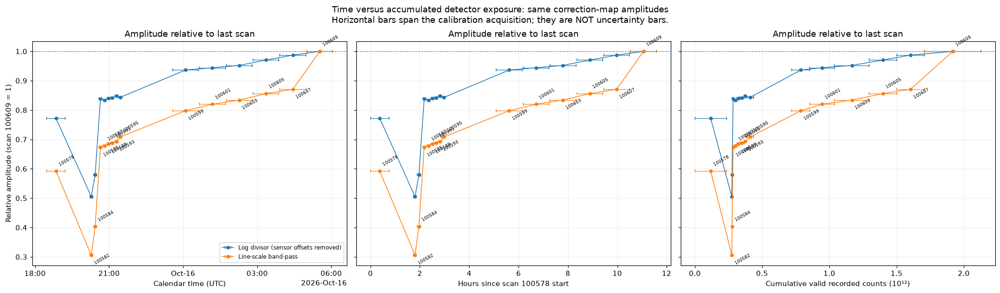

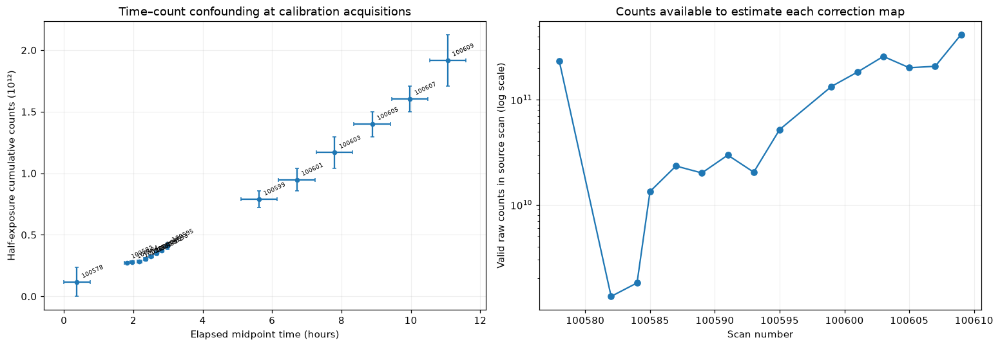

Time versus half-exposure cumulative counts, Pearson r = 0.9932; not a causal test.
Acquisition window (UTC): 2026-10-15 18:28:18.692000+00:00 to 2026-10-16 06:03:27.156000+00:00
Intervening-acquisition counts included: 324,436,075,017


,start_utc,end_utc,elapsed_midpoint_hours,frames,valid_raw_counts,cumulative_counts_before,cumulative_counts_after,amplitude_log_divisor,amplitude_line_bandpass
scan,,,,,,,,,
100578,2026-10-15 18:28:18.692000+00:00,2026-10-15 19:13:21.200000+00:00,0.375348,81,2.343364e+11,0.000000e+00,2.343364e+11,0.772041,0.592170
100582,2026-10-15 20:13:11.601000+00:00,2026-10-15 20:20:12.821000+00:00,1.806533,310,1.341866e+09,2.741813e+11,2.755232e+11,0.505073,0.306064
100584,2026-10-15 20:22:35.862000+00:00,2026-10-15 20:29:36.196000+00:00,1.963149,310,1.803609e+09,2.755257e+11,2.773293e+11,0.579500,0.403610
100585,2026-10-15 20:35:23.749000+00:00,2026-10-15 20:42:28.820000+00:00,2.177109,31,1.338442e+10,2.773293e+11,2.907137e+11,0.838494,0.673724
100587,2026-10-15 20:46:02.022000+00:00,2026-10-15 20:53:03.129000+00:00,2.353857,310,2.342070e+10,2.907413e+11,3.141620e+11,0.834002,0.678809
100589,2026-10-15 20:55:24.164000+00:00,2026-10-15 21:02:27.727000+00:00,2.510348,310,2.010948e+10,3.141849e+11,3.342944e+11,0.840268,0.684601
100591,2026-10-15 21:04:44.549000+00:00,2026-10-15 21:11:45.413000+00:00,2.665636,310,2.974748e+10,3.343391e+11,3.640865e+11,0.840885,0.688022
100593,2026-10-15 21:14:10.171000+00:00,2026-10-15 21:21:12.010000+00:00,2.822888,310,2.045435e+10,3.641128e+11,3.845671e+11,0.848656,0.692434
100595,2026-10-15 21:23:32.263000+00:00,2026-10-15 21:30:33.567000+00:00,2.978951,310,5.210383e+10,3.846433e+11,4.367472e+11,0.843233,0.708256


Source matching, cumulative-count conservation and reference-amplitude checks passed.


In [21]:
import matplotlib.dates as mdates
from datetime import timezone

amplitude_exposure = exposure_ledger.loc[scans].copy()
amplitude_exposure['amplitude_log_divisor'] = xcorr_table.loc['log_divisor', 'zero_lag_amplitude'].reindex(scans)
amplitude_exposure['amplitude_line_bandpass'] = xcorr_table.loc['line_bandpass', 'zero_lag_amplitude'].reindex(scans)
if amplitude_exposure[['amplitude_log_divisor', 'amplitude_line_bandpass']].isna().any().any():
    raise ValueError('Missing amplitude/source matches.')

elapsed_start = (amplitude_exposure['start_utc'] - exposure_origin).dt.total_seconds().to_numpy() / 3600
elapsed_end = (amplitude_exposure['end_utc'] - exposure_origin).dt.total_seconds().to_numpy() / 3600
elapsed_middle = amplitude_exposure['elapsed_midpoint_hours'].to_numpy()
time_half_width = 0.5 * (elapsed_end - elapsed_start)
count_middle = amplitude_exposure['cumulative_counts_half_exposure'].to_numpy() / 1e12
count_half_width = 0.5 * amplitude_exposure['valid_raw_counts'].to_numpy() / 1e12
utc_dates = mdates.date2num(amplitude_exposure['midpoint_utc'].dt.to_pydatetime())

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True, constrained_layout=True)
x_definitions = ((utc_dates, time_half_width / 24, 'Calendar time (UTC)'),
                 (elapsed_middle, time_half_width, f'Hours since scan {EXPOSURE_FIRST_SCAN} start'),
                 (count_middle, count_half_width, 'Cumulative valid recorded counts (10¹²)'))
for field, color, label_text in (
    ('amplitude_log_divisor', 'tab:blue', 'Log divisor (sensor offsets removed)'),
    ('amplitude_line_bandpass', 'tab:orange', 'Line-scale band-pass')):
    y = amplitude_exposure[field].to_numpy()
    for ax, (x, xwidth, xlabel) in zip(axes, x_definitions):
        ax.errorbar(x, y, xerr=xwidth, fmt='o-', color=color, linewidth=1,
                     elinewidth=0.8, capsize=2, markersize=4, label=label_text)
        ax.set_xlabel(xlabel)
        if field == 'amplitude_line_bandpass':
            for j, scan in enumerate(scans):
                ax.annotate(str(scan), (x[j], y[j]), xytext=(3, -13 if j % 2 else 7),
                            textcoords='offset points', fontsize=6, rotation=30)
for ax in axes:
    ax.axhline(1, color='0.5', ls='--', lw=0.8)
    ax.grid(alpha=0.2)
    ax.set_title('Amplitude relative to last scan')
axes[0].set_ylabel(f'Relative amplitude (scan {xcorr_reference_scan} = 1)')
locator = mdates.AutoDateLocator(minticks=3, maxticks=6, tz=timezone.utc)
axes[0].xaxis.set_major_locator(locator)
axes[0].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=timezone.utc))
axes[0].legend(fontsize=8, loc='best')
fig.suptitle('Time versus accumulated detector exposure: same correction-map amplitudes\n'
             'Horizontal bars span the calibration acquisition; they are NOT uncertainty bars.')
plt.show()

# Additional context: how strongly are the proposed x-axes coupled, and how many counts
# supported each calibration? No model selection or causal claim is made from these plots.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
axes[0].errorbar(elapsed_middle, count_middle, xerr=time_half_width, yerr=count_half_width,
                 fmt='o', capsize=2, markersize=4)
axes[0].set(title='Time–count confounding at calibration acquisitions',
            xlabel='Elapsed midpoint time (hours)', ylabel='Half-exposure cumulative counts (10¹²)')
per_scan_counts = amplitude_exposure['valid_raw_counts'].to_numpy()
axes[1].semilogy(scans, per_scan_counts, 'o-')
axes[1].set(title='Counts available to estimate each correction map', xlabel='Scan number',
            ylabel='Valid raw counts in source scan (log scale)')
axes[1].ticklabel_format(axis='x', style='plain', useOffset=False)
for j, scan in enumerate(scans):
    axes[0].annotate(str(scan), (elapsed_middle[j], count_middle[j]), xytext=(4, 4),
                     textcoords='offset points', fontsize=6, rotation=25)
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()
time_count_r = float(np.corrcoef(elapsed_middle, count_middle)[0, 1]) if len(scans) > 1 else np.nan
print(f'Time versus half-exposure cumulative counts, Pearson r = {time_count_r:.4f}; not a causal test.')
print('Acquisition window (UTC):', exposure_ledger['start_utc'].min(), 'to', exposure_ledger['end_utc'].max())
print('Intervening-acquisition counts included:',
      f'{exposure_ledger.loc[~exposure_ledger["is_calibration_scan"], "valid_raw_counts"].sum():,.0f}')
display(amplitude_exposure[['start_utc', 'end_utc', 'elapsed_midpoint_hours', 'frames',
                            'valid_raw_counts', 'cumulative_counts_before', 'cumulative_counts_after',
                            'amplitude_log_divisor', 'amplitude_line_bandpass']])
# Check correct provenance, nondecreasing exposure and final-reference normalization.
for scan in scans:
    assert Path(amplitude_exposure.loc[scan, 'nexus_path']).resolve() == source_scan_paths[int(scan)].resolve()
assert (amplitude_exposure['cumulative_counts_before'] <= amplitude_exposure['cumulative_counts_after']).all()
np.testing.assert_allclose(amplitude_exposure.loc[xcorr_reference_scan,
                           ['amplitude_log_divisor', 'amplitude_line_bandpass']].to_numpy(dtype=float), 1, atol=1e-10)
print('Source matching, cumulative-count conservation and reference-amplitude checks passed.')

## Quiet-patch noise benchmark versus coherent wavy-line signal

**Use fixed, independently selected control patches—not the smoothest pixels of each scan.** Nonoverlapping square tiles wholly inside the common line-analysis support are ranked by RMS ridge response in the earlier multi-scan template (`TEMPLATE_SCANS`). Within **each sensor**, the lowest quarter become quiet controls and the highest quarter become line-rich patches; the middle half is unused. Both classes have the same number/size of tiles per sensor. This reuses the line-response morphology without ranking the noise of the scan being tested. Template-building scans are explicitly flagged as self-included. Quiet means *relatively line-poor in the template*, not feature-free in every scan; inspect the overlays.

All statistics use saved divisor maps; no additional raw-frame pass is required. Patch means are removed to avoid sensor/broad offsets.

- **Quiet high-pass MAD sigma:** robust fine-scale fluctuation proxy in the controls, including any stable pixel texture. Not an absolute Poisson uncertainty.
- **Quiet band-pass RMS:** empirical fluctuations at the *same spatial scale* as the wavy-line signal. Line-rich RMS and the signed difference `rich variance − quiet variance` are shown separately. A negative difference is allowed. Subtracting these variances assumes comparable noise in both regions; no automatic 'noise-corrected truth' is claimed.
- **Coherent amplitude:** signed fit of line-rich patches to the fixed template, with an intercept per patch. Its fitted RMS divided by quiet band-pass RMS is a **spatial contrast-to-background ratio**, not precision of the mean.
- **Quiet-block amplitude scatter:** replace each line-rich patch with a randomly sampled quiet patch **from the same sensor**, apply a random ± sign and project onto the fixed template. The scatter of these null amplitudes benchmarks how much quiet fluctuations can imitate the coherent pattern. Whole patches preserve within-patch correlations; it does not treat pixels as independent. Bars are ±1 empirical null SD, **not validated confidence intervals or Poisson error bars**. The amplitude/scatter ratio is an empirical SNR proxy, not a calibrated significance or p-value.

The resampling assumes quiet patches represent the noise at line-rich locations and that independent block/sign draws are appropriate. It omits cross-patch correlations and uncertainty in the template, can fail for unequal illumination or detector response, and includes genuine quiet-region structure. It benchmarks random pattern mimicry, not scan-to-scan amplitude bias. Repeat with other patch sizes and template scans before physical conclusions. Truly separating counting noise requires independently fitted repeat/split data or per-pixel count/fit-uncertainty information; whole-scan raw count totals alone are not local uncertainties.

Template-only selection scans: (100599, 100603, 100607)
No tested scan is allowed to reselect its own controls.
Quiet / line-rich pixels: 21504 21504


/tmp/ipykernel_3347542/3847217139.py:35: UserWarning: Sensor 2 excluded: fewer than two quiet/rich patches available.
  warnings.warn(f'Sensor {sensor} excluded: fewer than two quiet/rich patches available.')
/tmp/ipykernel_3347542/3847217139.py:35: UserWarning: Sensor 4 excluded: fewer than two quiet/rich patches available.
  warnings.warn(f'Sensor {sensor} excluded: fewer than two quiet/rich patches available.')


patches              template_ridge_median                    
role   line-rich quiet unused             line-rich     quiet    unused
sensor                                                                 
1            2.0   2.0    4.0              0.524256  0.393233  0.448234
2            NaN   NaN    3.0                   NaN       NaN  0.392040
3            2.0   2.0    4.0              0.510729  0.386138  0.433678
4            NaN   NaN    2.0                   NaN       NaN  0.458830
5            3.0   3.0    7.0              0.478086  0.394193  0.417122
6            4.0   4.0    9.0              0.487257  0.377006  0.439772
7            8.0   8.0   17.0              0.596472  0.371156  0.429684
8            2.0   2.0    4.0              0.854479  0.377082  0.449479

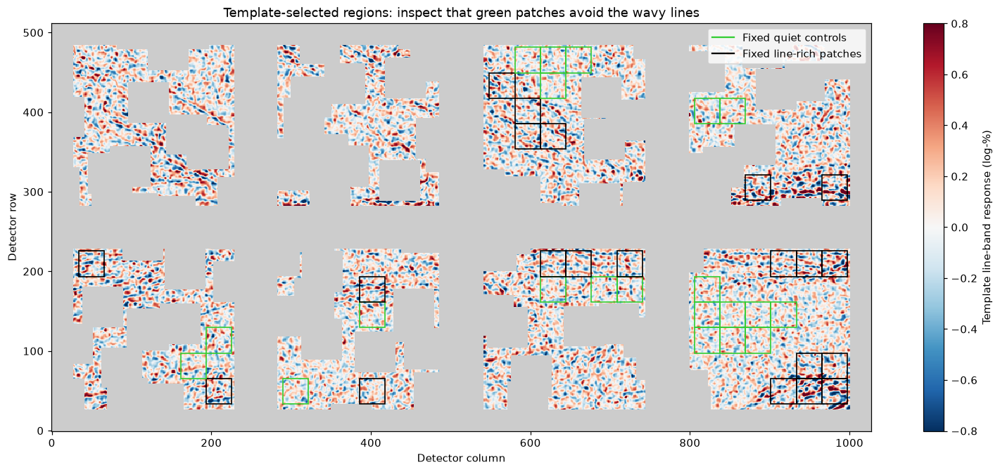

In [22]:
QUIET_PATCH_SIZE = 32  # Try 24 or 40 as a sensitivity check; >= spatial filter scale.
QUIET_PATCH_FRACTION = 0.25  # Lowest/highest fraction of eligible tiles, independently per sensor.
QUIET_NULL_REPEATS = 1000
QUIET_RANDOM_SEED = 45166
if not isinstance(QUIET_PATCH_SIZE, (int, np.integer)) or QUIET_PATCH_SIZE < 8:
    raise ValueError('QUIET_PATCH_SIZE must be an integer >= 8.')
if QUIET_PATCH_SIZE < 4 * max(LINE_BAND_SIGMAS):
    raise ValueError('Use patches at least four times the largest line-band sigma.')
if not 0 < QUIET_PATCH_FRACTION <= 0.5:
    raise ValueError('QUIET_PATCH_FRACTION must be in (0, 0.5].')
if not isinstance(QUIET_NULL_REPEATS, (int, np.integer)) or QUIET_NULL_REPEATS < 100:
    raise ValueError('Use at least 100 quiet-block resamples.')
quiet_tile_rows = []
for sensor in range(8):
    rr, cc = np.where(sensor_ids == sensor)
    if not rr.size:
        continue
    for r0 in range(int(rr.min()), int(rr.max()) + 2 - QUIET_PATCH_SIZE, QUIET_PATCH_SIZE):
        for c0 in range(int(cc.min()), int(cc.max()) + 2 - QUIET_PATCH_SIZE, QUIET_PATCH_SIZE):
            region = np.s_[r0:r0 + QUIET_PATCH_SIZE, c0:c0 + QUIET_PATCH_SIZE]
            if not (line_support[region].all() and np.all(sensor_ids[region] == sensor)):
                continue
            strength = line_template_ridge[region]
            quiet_tile_rows.append({'sensor': sensor + 1, 'row': r0, 'column': c0,
                                    'template_ridge_rms': float(np.sqrt(np.mean(strength**2))),
                                    'role': 'unused'})
quiet_patch_table = pd.DataFrame(quiet_tile_rows)
if quiet_patch_table.empty:
    raise ValueError('No wholly valid patches. Reduce patch size/scan selection or inspect support.')
quiet_patch_groups = {}
for sensor, group in quiet_patch_table.groupby('sensor'):
    ranked = group.sort_values(['template_ridge_rms', 'row', 'column']).index.to_numpy()
    n_select = int(np.floor(len(ranked) * QUIET_PATCH_FRACTION))
    if n_select < 2:
        warnings.warn(f'Sensor {sensor} excluded: fewer than two quiet/rich patches available.')
        continue
    quiet_patch_table.loc[ranked[:n_select], 'role'] = 'quiet'
    quiet_patch_table.loc[ranked[-n_select:], 'role'] = 'line-rich'
    quiet_patch_groups[int(sensor)] = {'quiet': ranked[:n_select], 'line-rich': ranked[-n_select:]}
if not quiet_patch_groups:
    raise ValueError('No sensor has enough independent patches. Adjust patch size/fraction.')
quiet_control_mask = np.zeros_like(common_valid)
quiet_rich_mask = np.zeros_like(common_valid)


def quiet_patch_region(index):
    tile = quiet_patch_table.loc[index]
    r0, c0 = int(tile['row']), int(tile['column'])
    return np.s_[r0:r0 + QUIET_PATCH_SIZE, c0:c0 + QUIET_PATCH_SIZE]


def quiet_patch_vectors(values, indices):
    stack = np.stack([values[quiet_patch_region(index)].ravel() for index in indices])
    return stack - stack.mean(axis=1, keepdims=True)


for role, target_mask in (('quiet', quiet_control_mask), ('line-rich', quiet_rich_mask)):
    for index in quiet_patch_table.index[quiet_patch_table['role'] == role]:
        target_mask[quiet_patch_region(index)] = True
assert not np.any(quiet_control_mask & quiet_rich_mask)
assert np.all((quiet_control_mask | quiet_rich_mask) <= line_support)
print('Template-only selection scans:', TEMPLATE_SCANS)
print('No tested scan is allowed to reselect its own controls.')
print('Quiet / line-rich pixels:', int(quiet_control_mask.sum()), int(quiet_rich_mask.sum()))
quiet_patch_inventory = quiet_patch_table.groupby(['sensor', 'role']).agg(
    patches=('row', 'size'), template_ridge_median=('template_ridge_rms', 'median')).unstack('role')
display(quiet_patch_inventory)

from matplotlib.patches import Rectangle
fig, ax = plt.subplots(figsize=(15, 6), constrained_layout=True)
image = ax.imshow(np.ma.array(line_template_band, mask=~line_support), origin='lower',
                   cmap=ridge_cmap, vmin=-line_plot_limit, vmax=line_plot_limit, interpolation='nearest')
for index, tile in quiet_patch_table.iterrows():
    if tile['role'] == 'unused':
        continue
    color = 'limegreen' if tile['role'] == 'quiet' else 'black'
    ax.add_patch(Rectangle((tile['column'] - 0.5, tile['row'] - 0.5), QUIET_PATCH_SIZE,
                            QUIET_PATCH_SIZE, fill=False, edgecolor=color, linewidth=1.1))
ax.plot([], [], color='limegreen', label='Fixed quiet controls')
ax.plot([], [], color='black', label='Fixed line-rich patches')
ax.legend(loc='upper right')
ax.set(title='Template-selected regions: inspect that green patches avoid the wavy lines',
       xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=ax, label='Template line-band response (log-%)')
plt.show()

Empirical controls, not certified Poisson uncertainties; self-included template scans are flagged.


,template_training_scan,quiet_highpass_sigma,quiet_band_rms,rich_band_rms,rich_minus_quiet_variance,rich_template_amplitude,rich_unmatched_rms,fitted_signal_rms,contrast_to_quiet_ratio,quiet_block_amplitude_sd,amplitude_over_quiet_block_sd
scan,,,,,,,,,,,
100578,False,1.1779,0.1909,0.2573,0.0298,0.6715,0.1101,0.2326,1.2183,0.0118,56.9124
100582,False,3.0759,0.5196,0.5472,0.0294,0.4050,0.5289,0.1403,0.2700,0.0307,13.2034
100584,False,2.7559,0.4840,0.5122,0.0281,0.5621,0.4738,0.1947,0.4023,0.0327,17.1718
100585,False,1.4927,0.2561,0.3322,0.0448,0.8029,0.1817,0.2781,1.0861,0.0175,45.8224
100587,False,1.3858,0.2346,0.3163,0.0450,0.8101,0.1460,0.2806,1.1962,0.0150,54.1048
100589,False,1.3774,0.2304,0.3184,0.0483,0.8125,0.1488,0.2815,1.2215,0.0125,64.8953
100591,False,1.3795,0.2324,0.3174,0.0467,0.8150,0.1451,0.2823,1.2145,0.0135,60.3375
100593,False,1.4143,0.2379,0.3191,0.0452,0.8127,0.1502,0.2815,1.1835,0.0164,49.6501
100595,False,1.3118,0.2206,0.3097,0.0472,0.8171,0.1257,0.2831,1.2830,0.0134,60.8463


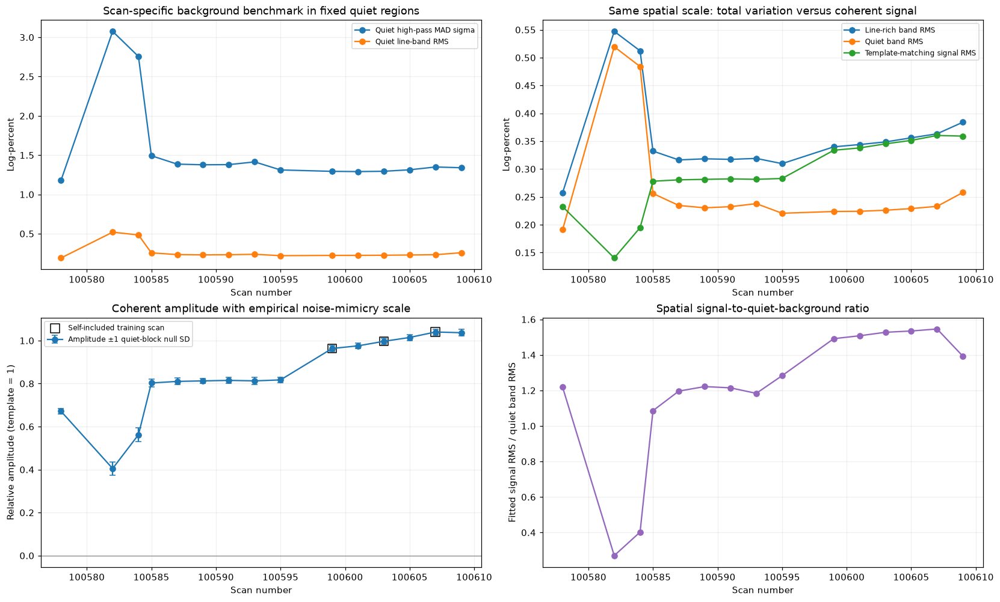

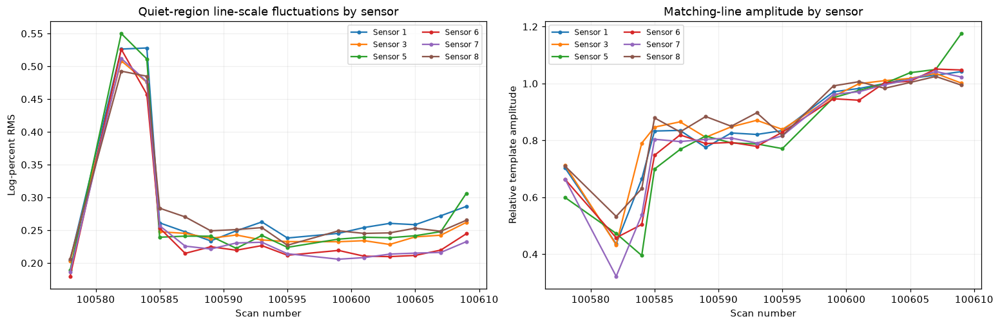

In [23]:
quiet_noise_rows, quiet_sensor_rows = [], []
quiet_null_samples = {}
quiet_rng = np.random.default_rng(QUIET_RANDOM_SEED)
quiet_templates = {sensor: quiet_patch_vectors(line_template_band, group['line-rich'])
                   for sensor, group in quiet_patch_groups.items()}
quiet_template_energy = sum(float(np.sum(values**2)) for values in quiet_templates.values())
quiet_rich_pixel_number = sum(values.size for values in quiet_templates.values())
quiet_template_rms = np.sqrt(quiet_template_energy / quiet_rich_pixel_number)
if quiet_template_energy <= 1e-12:
    raise ValueError('Selected line-rich template has negligible contrast.')
for i, scan in enumerate(scans):
    numerator, rich_energy, control_energy = 0.0, 0.0, 0.0
    highpass_controls = []
    null_numerator = np.zeros(QUIET_NULL_REPEATS)
    rich_values_by_sensor = {}
    for sensor, group in quiet_patch_groups.items():
        template_values = quiet_templates[sensor]
        controls = quiet_patch_vectors(line_band_maps[i], group['quiet'])
        rich_values = quiet_patch_vectors(line_band_maps[i], group['line-rich'])
        rich_values_by_sensor[sensor] = rich_values
        fine_controls = quiet_patch_vectors(highpass[i], group['quiet'])
        highpass_controls.append(fine_controls.ravel())
        numerator += float(np.sum(template_values * rich_values))
        rich_energy += float(np.sum(rich_values**2))
        control_energy += float(np.sum(controls**2))
        # Dot products of whole quiet patches with each rich template patch.
        # No per-pixel shuffling, rotation or variance renormalization.
        projections = template_values @ controls.T
        choices = quiet_rng.integers(0, len(controls), size=(QUIET_NULL_REPEATS, len(template_values)))
        signs = quiet_rng.choice((-1.0, 1.0), size=choices.shape)
        null_numerator += np.sum(projections[np.arange(len(template_values))[None, :], choices] * signs, axis=1)
        template_energy_sensor = float(np.sum(template_values**2))
        sensor_amplitude = (float(np.sum(template_values * rich_values)) / template_energy_sensor
                            if template_energy_sensor > 1e-12 else np.nan)
        quiet_sensor_rows.append({'scan': scan, 'sensor': sensor,
                                  'quiet_patches': len(controls),
                                  'quiet_highpass_sigma': robust_sigma(fine_controls.ravel()),
                                  'quiet_band_rms': np.sqrt(np.mean(controls**2)),
                                  'rich_band_rms': np.sqrt(np.mean(rich_values**2)),
                                  'rich_template_amplitude': sensor_amplitude})
    amplitude = numerator / quiet_template_energy
    control_variance = control_energy / quiet_rich_pixel_number
    rich_variance = rich_energy / quiet_rich_pixel_number
    null_amplitudes = null_numerator / quiet_template_energy
    quiet_null_samples[int(scan)] = null_amplitudes
    null_sd = float(np.std(null_amplitudes, ddof=1))
    residual_energy = sum(float(np.sum((rich_values_by_sensor[sensor] - amplitude * quiet_templates[sensor])**2))
                          for sensor in quiet_templates)
    quiet_noise_rows.append({'scan': scan, 'template_training_scan': int(scan) in TEMPLATE_SCANS,
                             'quiet_highpass_sigma': robust_sigma(np.concatenate(highpass_controls)),
                             'quiet_band_rms': np.sqrt(control_variance),
                             'rich_band_rms': np.sqrt(rich_variance),
                             'rich_minus_quiet_variance': rich_variance - control_variance,
                             'rich_template_amplitude': amplitude,
                             'rich_unmatched_rms': np.sqrt(residual_energy / quiet_rich_pixel_number),
                             'fitted_signal_rms': abs(amplitude) * quiet_template_rms,
                             'contrast_to_quiet_ratio': abs(amplitude) * quiet_template_rms / np.sqrt(control_variance)
                                                        if control_variance > 0 else np.nan,
                             'quiet_block_amplitude_sd': null_sd,
                             'amplitude_over_quiet_block_sd': amplitude / null_sd if null_sd > 0 else np.nan})
quiet_noise_benchmark = pd.DataFrame(quiet_noise_rows).set_index('scan')
quiet_sensor_benchmark = pd.DataFrame(quiet_sensor_rows).set_index(['scan', 'sensor'])
print('Empirical controls, not certified Poisson uncertainties; self-included template scans are flagged.')
display(quiet_noise_benchmark.round(4))

fig, axes = plt.subplots(2, 2, figsize=(15, 9), constrained_layout=True)
axes[0, 0].plot(scans, quiet_noise_benchmark['quiet_highpass_sigma'], 'o-', label='Quiet high-pass MAD sigma')
axes[0, 0].plot(scans, quiet_noise_benchmark['quiet_band_rms'], 'o-', label='Quiet line-band RMS')
axes[0, 0].set(title='Scan-specific background benchmark in fixed quiet regions', ylabel='Log-percent')
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(scans, quiet_noise_benchmark['rich_band_rms'], 'o-', label='Line-rich band RMS')
axes[0, 1].plot(scans, quiet_noise_benchmark['quiet_band_rms'], 'o-', label='Quiet band RMS')
axes[0, 1].plot(scans, quiet_noise_benchmark['fitted_signal_rms'], 'o-', label='Template-matching signal RMS')
axes[0, 1].set(title='Same spatial scale: total variation versus coherent signal', ylabel='Log-percent')
axes[0, 1].legend(fontsize=8)
axes[1, 0].errorbar(scans, quiet_noise_benchmark['rich_template_amplitude'],
                   yerr=quiet_noise_benchmark['quiet_block_amplitude_sd'], fmt='o-', capsize=3,
                   label='Amplitude ±1 quiet-block null SD')
training_mask = quiet_noise_benchmark['template_training_scan'].to_numpy()
axes[1, 0].scatter(scans[training_mask], quiet_noise_benchmark.loc[training_mask, 'rich_template_amplitude'],
                   marker='s', s=90, facecolors='none', edgecolors='black', label='Self-included training scan')
axes[1, 0].set(title='Coherent amplitude with empirical noise-mimicry scale', ylabel='Relative amplitude (template = 1)')
axes[1, 0].axhline(0, color='0.5', lw=0.8)
axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(scans, quiet_noise_benchmark['contrast_to_quiet_ratio'], 'o-', color='tab:purple')
axes[1, 1].set(title='Spatial signal-to-quiet-background ratio', ylabel='Fitted signal RMS / quiet band RMS')
for ax in axes.flat:
    ax.set_xlabel('Scan number')
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.grid(alpha=0.2)
plt.show()

# Show sensor variation rather than hiding local noise heterogeneity in a global average.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), constrained_layout=True)
for sensor in quiet_patch_groups:
    data_sensor = quiet_sensor_benchmark.xs(sensor, level='sensor')
    axes[0].plot(scans, data_sensor['quiet_band_rms'], '.-', label=f'Sensor {sensor}')
    axes[1].plot(scans, data_sensor['rich_template_amplitude'], '.-', label=f'Sensor {sensor}')
axes[0].set(title='Quiet-region line-scale fluctuations by sensor', ylabel='Log-percent RMS')
axes[1].set(title='Matching-line amplitude by sensor', ylabel='Relative template amplitude')
for ax in axes:
    ax.set_xlabel('Scan number')
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
    ax.legend(ncol=2, fontsize=8)
    ax.grid(alpha=0.2)
plt.show()

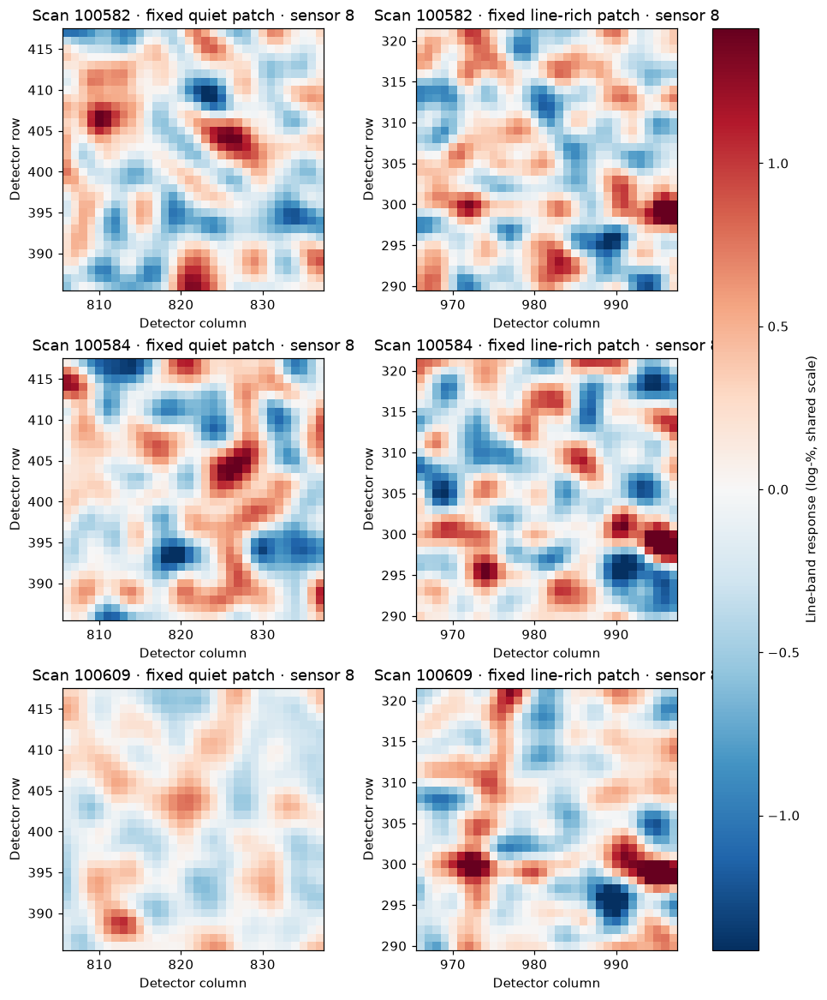

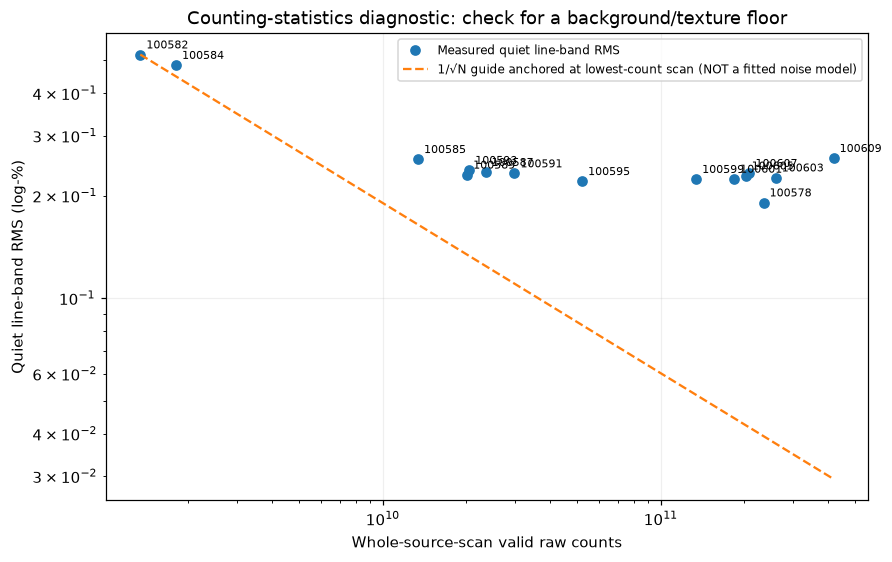

Quiet-control checks passed: disjoint fixed support, same-sensor balance, unit/amplitude recovery,
signed-noise cancellation and proportional null-scatter scaling.
Sensors included: [1, 3, 5, 6, 7, 8] ; excluded sensors have insufficient fully supported tiles.
Treat empirical amplitude/scatter ratios as diagnostics, NOT calibrated detection significance.
Combined map/amplitude and quiet-control results are available as quiet_benchmark_trends.


In [24]:
# Fixed quiet/rich zooms from the same sensor with the clearest template separation.
quiet_example_sensor = max(quiet_patch_groups, key=lambda sensor:
    quiet_patch_table.loc[quiet_patch_groups[sensor]['line-rich'], 'template_ridge_rms'].median()
    - quiet_patch_table.loc[quiet_patch_groups[sensor]['quiet'], 'template_ridge_rms'].median())
quiet_example_indices = [quiet_patch_table.loc[quiet_patch_groups[quiet_example_sensor]['quiet'],
                                               'template_ridge_rms'].idxmin(),
                         quiet_patch_table.loc[quiet_patch_groups[quiet_example_sensor]['line-rich'],
                                               'template_ridge_rms'].idxmax()]
quiet_example_scans = list(dict.fromkeys([s for s in (100582, 100584, int(scans[-1])) if s in files.index]))
quiet_zoom_values = [line_band_maps[int(np.flatnonzero(scans == scan)[0])][quiet_patch_region(index)]
                     for scan in quiet_example_scans for index in quiet_example_indices]
quiet_zoom_limit = max(float(np.percentile(np.abs(np.concatenate([v.ravel() for v in quiet_zoom_values])), 99)), 1e-6)
fig, axes = plt.subplots(len(quiet_example_scans), 2, figsize=(9, 3.5 * len(quiet_example_scans)),
                         squeeze=False, constrained_layout=True)
for row, scan in enumerate(quiet_example_scans):
    i = int(np.flatnonzero(scans == scan)[0])
    for col, (index, role) in enumerate(zip(quiet_example_indices, ('quiet', 'line-rich'))):
        region = quiet_patch_region(index)
        image = axes[row, col].imshow(line_band_maps[i][region], origin='lower', cmap=ridge_cmap,
                                      vmin=-quiet_zoom_limit, vmax=quiet_zoom_limit, interpolation='nearest',
                                      extent=(region[1].start - 0.5, region[1].stop - 0.5,
                                              region[0].start - 0.5, region[0].stop - 0.5))
        axes[row, col].set(title=f'Scan {scan} · fixed {role} patch · sensor {quiet_example_sensor}',
                           xlabel='Detector column', ylabel='Detector row')
fig.colorbar(image, ax=axes.ravel().tolist(), label='Line-band response (log-%, shared scale)')
plt.show()

# Local illumination is not inferred from a whole-scan count total. This is only a sanity check.
if 'amplitude_exposure' in globals():
    quiet_count_context = quiet_noise_benchmark.join(amplitude_exposure[['valid_raw_counts']])
    fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    counts = quiet_count_context['valid_raw_counts'].to_numpy()
    fluctuations = quiet_count_context['quiet_band_rms'].to_numpy()
    ax.loglog(counts, fluctuations, 'o', label='Measured quiet line-band RMS')
    for scan, count, fluctuation in zip(scans, counts, fluctuations):
        ax.annotate(str(scan), (count, fluctuation), xytext=(4, 4), textcoords='offset points', fontsize=7)
    positive = counts > 0
    if positive.any():
        anchor = int(np.flatnonzero(positive)[np.argmin(counts[positive])])
        count_grid = np.geomspace(counts[positive].min(), counts[positive].max(), 100)
        ax.loglog(count_grid, fluctuations[anchor] * np.sqrt(counts[anchor] / count_grid), '--',
                   label='1/√N guide anchored at lowest-count scan (NOT a fitted noise model)')
    ax.set(xlabel='Whole-source-scan valid raw counts', ylabel='Quiet line-band RMS (log-%)',
           title='Counting-statistics diagnostic: check for a background/texture floor')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
    plt.show()

# Exact algebraic and support checks. Synthetic amplitudes must be recovered without clipping.
def quiet_rich_amplitude_from_patches(patches):
    return sum(float(np.sum(patches[sensor] * quiet_templates[sensor])) for sensor in quiet_templates) / quiet_template_energy

np.testing.assert_allclose(quiet_rich_amplitude_from_patches(quiet_templates), 1.0, atol=1e-12)
np.testing.assert_allclose(quiet_rich_amplitude_from_patches(
    {sensor: 0.4 * values for sensor, values in quiet_templates.items()}), 0.4, atol=1e-12)
check_rng = np.random.default_rng(45167)
check_noise = {sensor: check_rng.normal(size=values.shape) for sensor, values in quiet_templates.items()}
check_plus = {sensor: 0.4 * values + check_noise[sensor] for sensor, values in quiet_templates.items()}
check_minus = {sensor: 0.4 * values - check_noise[sensor] for sensor, values in quiet_templates.items()}
np.testing.assert_allclose(0.5 * (quiet_rich_amplitude_from_patches(check_plus)
                                + quiet_rich_amplitude_from_patches(check_minus)), 0.4, atol=1e-12)
# Scaling control fluctuations by two must scale the empirical amplitude scatter by two.
for null_samples in quiet_null_samples.values():
    np.testing.assert_allclose(np.std(2 * null_samples, ddof=1), 2 * np.std(null_samples, ddof=1), atol=1e-12)
assert np.isfinite(quiet_noise_benchmark.select_dtypes(include='number').to_numpy()).all()
for sensor, group in quiet_patch_groups.items():
    assert len(group['quiet']) == len(group['line-rich']) >= 2
assert quiet_control_mask.sum() == quiet_rich_mask.sum()
print('Quiet-control checks passed: disjoint fixed support, same-sensor balance, unit/amplitude recovery,')
print('signed-noise cancellation and proportional null-scatter scaling.')
print('Sensors included:', list(quiet_patch_groups), '; excluded sensors have insufficient fully supported tiles.')
print('Treat empirical amplitude/scatter ratios as diagnostics, NOT calibrated detection significance.')
quiet_benchmark_trends = trend_table_with_xcorr.join(
    quiet_noise_benchmark.drop(columns='template_training_scan').add_prefix('quietbenchmark_'))
print('Combined map/amplitude and quiet-control results are available as quiet_benchmark_trends.')

### Matching signal / quiet RMS versus scan, exposure and time

The **same spatial contrast-to-background ratio** (`contrast_to_quiet_ratio`) is plotted against three coordinates: scan number, cumulative valid recorded detector counts, and elapsed time. This is not the amplitude/quiet-block-scatter significance proxy. Cumulative counts include intervening acquisitions from the earlier ledger, relative to the configured exposure baseline; they are a flux/exposure proxy, not calibrated incident fluence or absorbed dose.

Exposure markers use the halfway accumulated counts within each calibration scan; time markers use the timestamp midpoint. Horizontal bars span each acquisition, **not uncertainty**. Open squares flag self-included template-building scans; other scans are held out of template construction. No additional raw-frame reads or changes to the ratio are made. Time and counts remain confounded, and both numerator and quiet-background denominator can change.

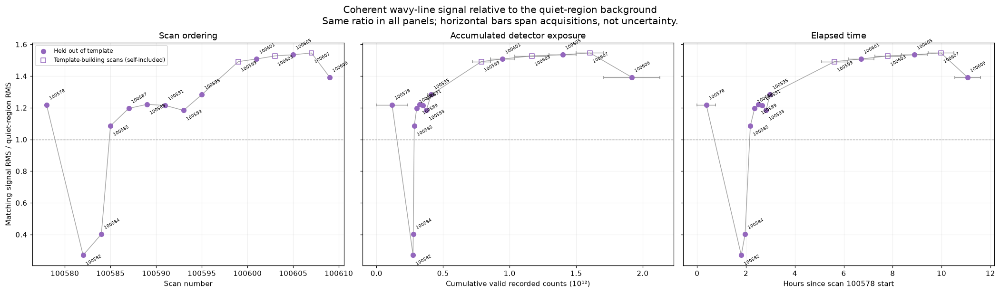

Verified: identical ratios in all three panels and scan-aligned acquisition coordinates.


,contrast_to_quiet_ratio,template_training_scan,midpoint_utc,elapsed_midpoint_hours,cumulative_counts_before,cumulative_counts_after
scan,,,,,,
100578,1.218297,False,2026-10-15 18:50:49.946000+00:00,0.375348,0.000000e+00,2.343364e+11
100582,0.270037,False,2026-10-15 20:16:42.211000+00:00,1.806533,2.741813e+11,2.755232e+11
100584,0.402294,False,2026-10-15 20:26:06.029000+00:00,1.963149,2.755257e+11,2.773293e+11
100585,1.086050,False,2026-10-15 20:38:56.284500+00:00,2.177109,2.773293e+11,2.907137e+11
100587,1.196188,False,2026-10-15 20:49:32.575500+00:00,2.353857,2.907413e+11,3.141620e+11
100589,1.221533,False,2026-10-15 20:58:55.945500+00:00,2.510348,3.141849e+11,3.342944e+11
100591,1.214517,False,2026-10-15 21:08:14.981000+00:00,2.665636,3.343391e+11,3.640865e+11
100593,1.183456,False,2026-10-15 21:17:41.090500+00:00,2.822888,3.641128e+11,3.845671e+11
100595,1.283037,False,2026-10-15 21:27:02.915000+00:00,2.978951,3.846433e+11,4.367472e+11


In [25]:
# Join explicitly by scan number; do not rely on the order of earlier plotting arrays.
quiet_ratio_axes = quiet_noise_benchmark[['contrast_to_quiet_ratio', 'template_training_scan']].join(
    amplitude_exposure[['start_utc', 'end_utc', 'midpoint_utc',
                        'cumulative_counts_before', 'cumulative_counts_after',
                        'cumulative_counts_half_exposure']], how='left', validate='one_to_one').reindex(scans)
if quiet_ratio_axes.isna().any().any():
    raise ValueError('Missing ratio or acquisition coordinates; run the quiet-benchmark and exposure cells first.')
ratio_values = quiet_ratio_axes['contrast_to_quiet_ratio'].to_numpy(dtype=float)
if not np.isfinite(ratio_values).all():
    raise ValueError('Matching-signal / quiet-RMS ratios must be finite.')
ratio_elapsed = (quiet_ratio_axes['midpoint_utc'] - exposure_origin).dt.total_seconds().to_numpy() / 3600
ratio_time_half_width = (quiet_ratio_axes['end_utc'] - quiet_ratio_axes['start_utc']).dt.total_seconds().to_numpy() / 7200
ratio_counts = quiet_ratio_axes['cumulative_counts_half_exposure'].to_numpy(dtype=float) / 1e12
ratio_count_half_width = (quiet_ratio_axes['cumulative_counts_after']
                          - quiet_ratio_axes['cumulative_counts_before']).to_numpy(dtype=float) / 2e12
if np.any(ratio_time_half_width < 0) or np.any(ratio_count_half_width < 0):
    raise ValueError('Negative acquisition interval width.')
ratio_training = quiet_ratio_axes['template_training_scan'].to_numpy(dtype=bool)

fig_quiet_ratio, ratio_axes = plt.subplots(1, 3, figsize=(19, 5.5), sharey=True, constrained_layout=True)
ratio_coordinates = (
    (scans, None, 'Scan number', 'Scan ordering'),
    (ratio_counts, ratio_count_half_width, 'Cumulative valid recorded counts (10¹²)', 'Accumulated detector exposure'),
    (ratio_elapsed, ratio_time_half_width, f'Hours since scan {EXPOSURE_FIRST_SCAN} start', 'Elapsed time'),
)
for ax, (coordinate, half_width, xlabel, title) in zip(ratio_axes, ratio_coordinates):
    ax.plot(coordinate, ratio_values, '-', color='0.65', linewidth=1, zorder=1)
    if half_width is not None:
        ax.errorbar(coordinate, ratio_values, xerr=half_width, fmt='none',
                     ecolor='0.55', elinewidth=0.9, capsize=2, zorder=1)
    for selected, marker, label_text in (
        (~ratio_training, 'o', 'Held out of template'),
        (ratio_training, 's', 'Template-building scans (self-included)'),
    ):
        ax.scatter(np.asarray(coordinate)[selected], ratio_values[selected], marker=marker,
                   s=40, facecolors='none' if marker == 's' else 'tab:purple',
                   edgecolors='tab:purple', label=label_text, zorder=3)
    for j, scan in enumerate(scans):
        ax.annotate(str(scan), (coordinate[j], ratio_values[j]),
                     xytext=(3, 7 if j % 2 == 0 else -14), textcoords='offset points',
                     fontsize=6, rotation=30)
    ax.axhline(1, color='0.5', ls='--', linewidth=0.8)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(alpha=0.2)
    ax.ticklabel_format(axis='x', style='plain', useOffset=False)
ratio_axes[0].set_ylabel('Matching signal RMS / quiet-region RMS')
ratio_axes[0].legend(fontsize=8, loc='best')
fig_quiet_ratio.suptitle(
    'Coherent wavy-line signal relative to the quiet-region background\n'
    'Same ratio in all panels; horizontal bars span acquisitions, not uncertainty.', fontsize=13)
plt.show()

quiet_ratio_axes['elapsed_midpoint_hours'] = ratio_elapsed
np.testing.assert_allclose(ratio_values, quiet_noise_benchmark.loc[scans, 'contrast_to_quiet_ratio'])
np.testing.assert_allclose(ratio_counts * 1e12,
    0.5 * (quiet_ratio_axes['cumulative_counts_before'] + quiet_ratio_axes['cumulative_counts_after']))
print('Verified: identical ratios in all three panels and scan-aligned acquisition coordinates.')
display(quiet_ratio_axes[['contrast_to_quiet_ratio', 'template_training_scan', 'midpoint_utc',
                         'elapsed_midpoint_hours', 'cumulative_counts_before', 'cumulative_counts_after']])

## Summary and interpretation checks

The tables below remain in memory only. Before interpreting a trend physically, compare source-frame and analysis-position counts in the metadata table; scan number is not elapsed time or dose. The common support removes changing masks from texture statistics but does not equalize photon statistics. No confidence intervals are inferred from spatially correlated detector pixels. Try a narrower `SCAN_RANGE`, another `REFERENCE_SCAN`, and several smoothing scales to check robustness.

In [13]:
trend_table = summary.join(texture).join(sensor_gain_table).join(ridge_trends).join(matched_lines)
assert trend_table.index.equals(files.index)
assert not texture.isna().any().any()
np.testing.assert_allclose(highpass[reference_index][common_valid] - highpass[reference_index][common_valid], 0)
# Multiplying a sensor by a constant must not alter its fine-scale texture.
scaled_divisor = records[reference_index]['combined_divisor'].copy()
scaled_divisor[sensor_ids == 0] *= 1.1
np.testing.assert_allclose(sensor_highpass(scaled_divisor)[common_valid],
                           highpass[reference_index][common_valid], atol=1e-10, rtol=1e-10)
print('Checks passed: fixed valid support, finite metrics, sensor-offset-invariant texture.')
print('Highest graininess (noise-sensitive; NOT a ranking of coherent line amplitude):')
display(texture.nlargest(min(3, len(scans)), 'robust_graininess'))
print('Recommended recurring-pattern comparison, with unmatched variation kept separate:')
display(matched_lines.round(4))
print('Sensor gain ranges across selected scans:')
display(pd.DataFrame({'minimum': sensor_gain_table.min(), 'maximum': sensor_gain_table.max(),
                      'peak_to_peak_percent_of_minimum': 100 * (sensor_gain_table.max() / sensor_gain_table.min() - 1)}))
print('Combined trend table (in memory; no files written):')
display(trend_table)


Checks passed: fixed valid support, finite metrics, sensor-offset-invariant texture.
Highest graininess (noise-sensitive; NOT a ranking of coherent line amplitude):


,robust_graininess,highpass_rms,highpass_p99_abs,neighbour_rms_over_sqrt2,highpass_change_rms
scan,,,,,
100582,3.083139,3.055922,7.808699,3.155710,3.102325
100584,2.848182,2.838386,7.304577,2.931313,2.791730
100585,1.615090,1.743652,5.000532,1.794009,1.059204


Recommended recurring-pattern comparison, with unmatched variation kept separate:


,template_training_scan,matched_line_amplitude,unmatched_rms_log_percent,template_correlation
scan,,,,
100578,False,0.6862,0.1070,0.9242
100582,False,0.4486,0.5242,0.3074
100584,False,0.5741,0.4808,0.4110
100585,False,0.8255,0.1780,0.8683
100587,False,0.8152,0.1432,0.9066
100589,False,0.8239,0.1478,0.9033
100591,False,0.8206,0.1431,0.9079
100593,False,0.8290,0.1491,0.9027
100595,False,0.8204,0.1224,0.9300


Sensor gain ranges across selected scans:


,minimum,maximum,peak_to_peak_percent_of_minimum
sensor_1,0.981214,0.989866,0.881842
sensor_2,1.008941,1.013760,0.477642
sensor_3,0.993030,0.996226,0.321915
sensor_4,0.984883,0.987235,0.238829
sensor_5,1.007143,1.010637,0.346904
sensor_6,0.990655,0.992981,0.234794
sensor_7,1.007199,1.012843,0.560352
sensor_8,1.009408,1.016445,0.697160


Combined trend table (in memory; no files written):


,collection,bad_candidates_total,bad_candidates_outside_base,base_mask_pixels,supported_valid_pixels,minimum_observations,geometry_hash,q_range,fit_bins,iterations,source_frames,analysis_positions,energy_kev,new_flags_vs_previous,cleared_flags_vs_previous,robust_graininess,highpass_rms,highpass_p99_abs,neighbour_rms_over_sqrt2,highpass_change_rms,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,ridge_rms,ridge_p99,connected_ridge_area_percent,connected_ridge_components,signed_ridge_change_rms,template_training_scan,matched_line_amplitude,unmatched_rms_log_percent,template_correlation
scan,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
100578,i15-1,39,39,17323,508974,8,4d3014efa448,"[200.0, 400.0]",800,10,81,81,76.7,NaN,NaN,1.301642,1.403900,3.986602,1.451622,0.000000,0.989866,1.013760,0.994938,0.987235,1.007143,0.990828,1.007199,1.009408,0.382219,1.013830,4.641382,303,0.000000,False,0.686152,0.107029,0.924218
100582,i15-1,1,1,17323,509012,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,0.0,38.0,3.083139,3.055922,7.808699,3.155710,3.102325,0.982377,1.010571,0.996226,0.984883,1.010637,0.990710,1.010143,1.015050,0.856015,2.071588,62.648381,15,0.896538,False,0.448638,0.524247,0.307430
100584,i15-1,1,1,17323,509012,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,0.0,0.0,2.848182,2.838386,7.304577,2.931313,2.791730,0.984072,1.011219,0.995954,0.985304,1.009753,0.990655,1.009562,1.014024,0.793080,1.927108,58.480622,17,0.816402,False,0.574078,0.480778,0.410961
100585,i15-1,21,21,17323,508992,8,4d3014efa448,"[200.0, 400.0]",800,10,31,31,76.7,20.0,0.0,1.615090,1.743652,5.000532,1.794009,1.059204,0.982498,1.010070,0.994004,0.985485,1.009948,0.992012,1.011723,1.014847,0.482973,1.281852,15.773536,749,0.372668,False,0.825459,0.178030,0.868297
100587,i15-1,30,30,17323,508983,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,9.0,0.0,1.514035,1.650962,4.786186,1.697932,0.854795,0.985108,1.011452,0.994371,0.986401,1.008802,0.991614,1.009888,1.012855,0.456489,1.231521,12.045903,584,0.316545,False,0.815209,0.143241,0.906613
100589,i15-1,31,31,17323,508982,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,3.0,2.0,1.533971,1.668729,4.827174,1.716853,0.887534,0.985348,1.011894,0.994456,0.986486,1.008772,0.991555,1.009481,1.012491,0.461903,1.241583,12.809738,629,0.324257,False,0.823869,0.147754,0.903261
100591,i15-1,29,29,17323,508984,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,1.0,3.0,1.521789,1.657889,4.798757,1.705016,0.856291,0.985691,1.011935,0.994365,0.986568,1.008622,0.991607,1.009367,1.012317,0.458600,1.227925,12.285037,629,0.316902,False,0.820630,0.143058,0.907881
100593,i15-1,31,31,17323,508982,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,2.0,0.0,1.555091,1.691336,4.896345,1.739065,0.925077,0.983673,1.010402,0.993863,0.985713,1.009502,0.992166,1.011143,1.014084,0.469150,1.253130,14.066102,692,0.336426,False,0.828958,0.149125,0.902748
100595,i15-1,36,36,17323,508977,8,4d3014efa448,"[200.0, 400.0]",800,10,310,31,76.7,5.0,0.0,1.460804,1.604550,4.686678,1.649356,0.710264,0.986901,1.012368,0.994481,0.987035,1.007924,0.991558,1.008658,1.011507,0.444215,1.197876,10.782906,533,0.275009,False,0.820416,0.122374,0.930039
